<a href="https://www.kaggle.com/code/manalrazak/pcb-detection?scriptVersionId=374100199" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# PCB Defect Classification

Detecting and classifying manufacturing defects on printed circuit boards using deep learning.

**6 defect classes:** Missing Hole · Mouse Bite · Open Circuit · Short · Spur · Spurious Copper

**3 models compared:** Custom CNN (baseline) · ResNet50 · MobileNetV2

**Dataset:** [PCB Defects — Kaggle](https://www.kaggle.com/datasets/akhatova/pcb-defects)

In [1]:
import os
import shutil
import random
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from pathlib import Path
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
import xml.etree.ElementTree as ET
from PIL import Image


print('All imports done')

All imports done


## Dataset Setup

This notebook uses the PCB Defects dataset from Kaggle.

**Option 1 — Kaggle notebook (recommended):**  
Add the dataset directly via *Add Data* → search "PCB Defects (akhatova)".

**Option 2 — Local setup:**  
1. Download your `kaggle.json` from kaggle.com → Settings → API
2. Place it at `~/.kaggle/kaggle.json`
3. Run:
```bash
kaggle datasets download -d akhatova/pcb-defects
unzip pcb-defects.zip -d pcb_data
```

In [2]:


if not os.path.exists('pcb_data/PCB_DATASET'):
    !kaggle datasets download -d akhatova/pcb-defects
    !unzip -q pcb-defects.zip -d pcb_data
    print('Downloaded and unzipped')
else:
    print('Dataset already exists, skipping download')

!ls pcb_data/PCB_DATASET

Dataset URL: https://www.kaggle.com/datasets/akhatova/pcb-defects
License(s): unknown
100%|███████████████████████████████████████| 1.88G/1.88G [00:11<00:00, 179MB/s]

Downloaded and unzipped
Annotations  images  PCB_USED  rotate.py  rotation


In [3]:
!ls pcb_data/PCB_DATASET

Annotations  images  PCB_USED  rotate.py  rotation


In [4]:
!ls pcb_data/PCB_DATASET/images
!ls pcb_data/PCB_DATASET/Annotations

Missing_hole  Mouse_bite  Open_circuit	Short  Spur  Spurious_copper
Missing_hole  Mouse_bite  Open_circuit	Short  Spur  Spurious_copper


In [5]:

base = 'pcb_data/PCB_DATASET/images'
for cls in os.listdir(base):
    count = len(os.listdir(os.path.join(base, cls)))
    print(f'{cls}: {count} images')

Short: 116 images
Spurious_copper: 116 images
Spur: 115 images
Mouse_bite: 115 images
Missing_hole: 115 images
Open_circuit: 116 images


In [6]:


sample_path = 'pcb_data/PCB_DATASET/images/Missing_hole'
sample_img = os.listdir(sample_path)[0]
img = Image.open(os.path.join(sample_path, sample_img))
print(f'Original image size: {img.size}')
print(f'Mode: {img.mode}')

Original image size: (3056, 2464)
Mode: RGB


In [7]:
shutil.rmtree('pcb_crops', ignore_errors=True)

annotations_dir = 'pcb_data/PCB_DATASET/Annotations'
images_dir = 'pcb_data/PCB_DATASET/images'
crops_dir = 'pcb_crops'
padding = 20  # extra pixels around each defect

os.makedirs(crops_dir, exist_ok=True)

crop_counts = {}
crop_id = 0

for cls_folder in os.listdir(annotations_dir):
    cls_path = os.path.join(annotations_dir, cls_folder)
    if not os.path.isdir(cls_path):
        continue

    os.makedirs(os.path.join(crops_dir, cls_folder), exist_ok=True)
    crop_counts[cls_folder] = 0

    for xml_file in os.listdir(cls_path):
        if not xml_file.endswith('.xml'):
            continue

        tree = ET.parse(os.path.join(cls_path, xml_file))
        root = tree.getroot()

        # Find matching image
        img_name = xml_file.replace('.xml', '.jpg')
        img_path = os.path.join(images_dir, cls_folder, img_name)

        if not os.path.exists(img_path):
            continue

        img = Image.open(img_path)
        w, h = img.size

        for obj in root.findall('object'):
            bbox = obj.find('bndbox')
            xmin = max(0, int(bbox.find('xmin').text) - padding)
            ymin = max(0, int(bbox.find('ymin').text) - padding)
            xmax = min(w, int(bbox.find('xmax').text) + padding)
            ymax = min(h, int(bbox.find('ymax').text) + padding)

            crop = img.crop((xmin, ymin, xmax, ymax))
            crop_path = os.path.join(crops_dir, cls_folder, f'{xml_file[:-4]}_{crop_id:05d}.jpg')
            crop.save(crop_path)
            crop_id += 1
            crop_counts[cls_folder] += 1

print('Cropping done!')
print('\nCrops per class:')
for cls, count in crop_counts.items():
    print(f'  {cls}: {count} crops')
print(f'\nTotal crops: {sum(crop_counts.values())}')

Cropping done!

Crops per class:
  Short: 491 crops
  Spurious_copper: 503 crops
  Spur: 488 crops
  Mouse_bite: 492 crops
  Missing_hole: 497 crops
  Open_circuit: 482 crops

Total crops: 2953


In [8]:
random.seed(42)
source_dir = 'pcb_crops'
output_dir = 'pcb_split'

if os.path.exists(output_dir):
    shutil.rmtree(output_dir)

# Split by BOARD so the same board never appears in train and test
boards = sorted({f.split('_')[0] for cls in os.listdir(source_dir)
                 for f in os.listdir(os.path.join(source_dir, cls))})
random.shuffle(boards)
test_boards, val_boards = set(boards[:2]), set(boards[2:4])
print('Test boards:', sorted(test_boards), '| Val boards:', sorted(val_boards))

for cls in os.listdir(source_dir):
    counts = {'train': 0, 'val': 0, 'test': 0}
    for split in counts:
        os.makedirs(f'{output_dir}/{split}/{cls}', exist_ok=True)
    for img in os.listdir(os.path.join(source_dir, cls)):
        board = img.split('_')[0]
        split = 'test' if board in test_boards else 'val' if board in val_boards else 'train'
        shutil.copy(os.path.join(source_dir, cls, img), f'{output_dir}/{split}/{cls}/{img}')
        counts[split] += 1
    print(f'{cls}: {counts}')

print('\nDone splitting!')

Test boards: ['06', '10'] | Val boards: ['05', '11']
Short: {'train': 330, 'val': 81, 'test': 80}
Spurious_copper: {'train': 321, 'val': 101, 'test': 81}
Spur: {'train': 314, 'val': 100, 'test': 74}
Mouse_bite: {'train': 313, 'val': 101, 'test': 78}
Missing_hole: {'train': 325, 'val': 96, 'test': 76}
Open_circuit: {'train': 319, 'val': 83, 'test': 80}

Done splitting!


In [9]:


# Image transforms
# Training uses augmentation (flips, rotations) to make the model more robust
# Val and test use only resize and normalize, no augmentation
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Load datasets from folders
train_data = datasets.ImageFolder('pcb_split/train', transform=train_transform)
val_data = datasets.ImageFolder('pcb_split/val', transform=eval_transform)
test_data = datasets.ImageFolder('pcb_split/test', transform=eval_transform)

# Create DataLoaders
train_loader = DataLoader(train_data, batch_size=32, shuffle=True, num_workers=0)
val_loader = DataLoader(val_data, batch_size=32, shuffle=False, num_workers=0)
test_loader = DataLoader(test_data, batch_size=32, shuffle=False, num_workers=0)

# Verify
print(f'Number of classes: {len(train_data.classes)}')
print(f'Classes: {train_data.classes}')
print(f'Train images: {len(train_data)}')
print(f'Val images: {len(val_data)}')
print(f'Test images: {len(test_data)}')

# Check if GPU is available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'\nDevice: {device}')

Number of classes: 6
Classes: ['Missing_hole', 'Mouse_bite', 'Open_circuit', 'Short', 'Spur', 'Spurious_copper']
Train images: 1922
Val images: 562
Test images: 469

Device: cuda


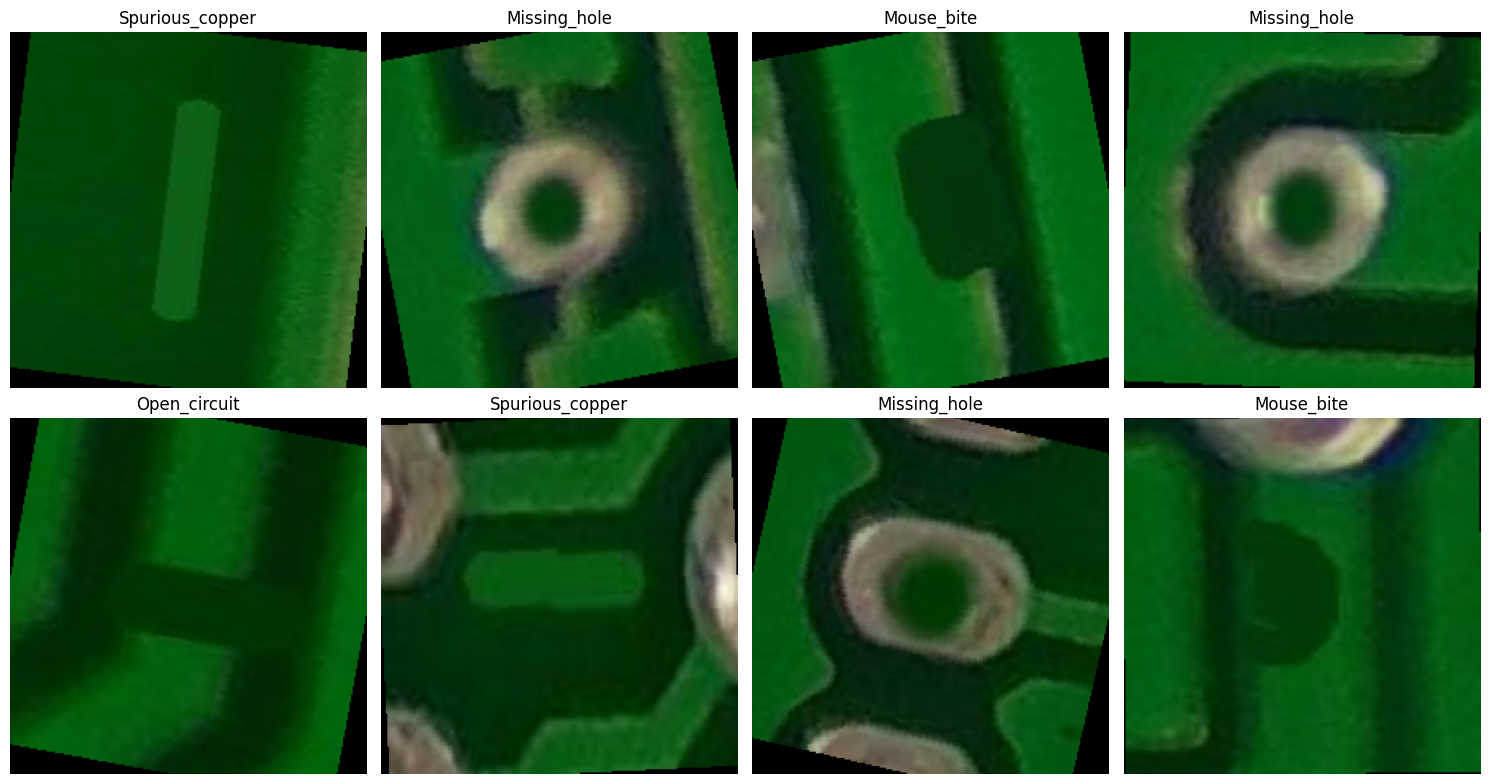

In [10]:


# Get one batch
images, labels = next(iter(train_loader))

# Function to unnormalize and display
def imshow(img):
    img = img.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = std * img + mean
    img = np.clip(img, 0, 1)
    return img

# Plot 8 samples
fig, axes = plt.subplots(2, 4, figsize=(15, 8))
for i, ax in enumerate(axes.flat):
    ax.imshow(imshow(images[i]))
    ax.set_title(train_data.classes[labels[i]])
    ax.axis('off')
plt.tight_layout()
plt.savefig('sample_images.png', dpi=100, bbox_inches='tight')
plt.show()

## Model 2 — ResNet50 (Transfer Learning)

Pretrained on ImageNet. All layers frozen except `layer4` and the final classifier,  
which is replaced with a 6-class linear layer. Fine-tuned with Adam (lr=0.0001).

In [11]:


# Load pretrained ResNet50
model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)

# Freeze all layers first
for param in model.parameters():
    param.requires_grad = False

# Unfreeze layer4 and fc layer
for param in model.layer4.parameters():
    param.requires_grad = True

# Replace final layer for 6 classes
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 6)

# fc layer is unfrozen by default since we just created it
model = model.to(device)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable parameters: {trainable_params:,}')
print(f'Model ready on: {device}')

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 243MB/s]


Trainable parameters: 14,977,030
Model ready on: cuda


In [12]:


# Loss function: measures how wrong the model's predictions are
criterion = nn.CrossEntropyLoss()

# Now optimize all unfrozen parameters, not just fc
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=0.0001)

print('Loss function: CrossEntropyLoss')
print('Optimizer: Adam, learning rate = 0.0001')


Loss function: CrossEntropyLoss
Optimizer: Adam, learning rate = 0.0001


In [13]:


num_epochs = 10
train_losses = []
val_losses = []
train_accs = []
val_accs = []

for epoch in range(num_epochs):
    start = time.time()

    # TRAINING PHASE
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward pass and weight update
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    train_loss = running_loss / total
    train_acc = 100. * correct / total
    train_losses.append(train_loss)
    train_accs.append(train_acc)

    # VALIDATION PHASE
    model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            val_total += labels.size(0)
            val_correct += predicted.eq(labels).sum().item()

    val_loss = val_running_loss / val_total
    val_acc = 100. * val_correct / val_total
    val_losses.append(val_loss)
    val_accs.append(val_acc)

    elapsed = time.time() - start
    print(f'Epoch {epoch+1}/{num_epochs} | Train Loss: {train_loss:.4f} Acc: {train_acc:.2f}% | Val Loss: {val_loss:.4f} Acc: {val_acc:.2f}% | Time: {elapsed:.1f}s')

print('\nTraining complete!')

Epoch 1/10 | Train Loss: 1.3191 Acc: 56.30% | Val Loss: 0.5796 Acc: 83.63% | Time: 15.1s
Epoch 2/10 | Train Loss: 0.3303 Acc: 91.52% | Val Loss: 0.1693 Acc: 93.42% | Time: 13.8s
Epoch 3/10 | Train Loss: 0.1247 Acc: 96.31% | Val Loss: 0.0730 Acc: 97.69% | Time: 14.1s
Epoch 4/10 | Train Loss: 0.0699 Acc: 97.87% | Val Loss: 0.0639 Acc: 97.86% | Time: 14.2s
Epoch 5/10 | Train Loss: 0.0584 Acc: 98.44% | Val Loss: 0.0518 Acc: 98.58% | Time: 14.3s
Epoch 6/10 | Train Loss: 0.0458 Acc: 98.65% | Val Loss: 0.0768 Acc: 97.86% | Time: 14.6s
Epoch 7/10 | Train Loss: 0.0386 Acc: 98.91% | Val Loss: 0.0523 Acc: 98.22% | Time: 14.8s
Epoch 8/10 | Train Loss: 0.0378 Acc: 99.06% | Val Loss: 0.0617 Acc: 98.40% | Time: 15.1s
Epoch 9/10 | Train Loss: 0.0285 Acc: 99.27% | Val Loss: 0.0455 Acc: 98.93% | Time: 14.9s
Epoch 10/10 | Train Loss: 0.0176 Acc: 99.38% | Val Loss: 0.0403 Acc: 98.75% | Time: 14.7s

Training complete!


In [14]:
import xml.etree.ElementTree as ET

annotation_path = 'pcb_data/PCB_DATASET/Annotations/Missing_hole'
sample_xml = os.listdir(annotation_path)[0]
tree = ET.parse(os.path.join(annotation_path, sample_xml))
root = tree.getroot()

print(f'File: {sample_xml}')
print(f'Image size: {root.find("size/width").text} x {root.find("size/height").text}')

for obj in root.findall('object'):
    name = obj.find('name').text
    bbox = obj.find('bndbox')
    xmin = bbox.find('xmin').text
    ymin = bbox.find('ymin').text
    xmax = bbox.find('xmax').text
    ymax = bbox.find('ymax').text
    print(f'Defect: {name} | Box: ({xmin},{ymin}) to ({xmax},{ymax})')

File: 01_missing_hole_02.xml
Image size: 3034 x 1586
Defect: missing_hole | Box: (2584,232) to (2650,298)
Defect: missing_hole | Box: (2366,803) to (2406,860)
Defect: missing_hole | Box: (1506,802) to (1559,856)


In [15]:
# Time just one batch on GPU
import time

model.train()
images, labels = next(iter(train_loader))
print(f'Images device before: {images.device}')

images, labels = images.to(device), labels.to(device)
print(f'Images device after: {images.device}')

start = time.time()
for i in range(10):
    outputs = model(images)
    loss = criterion(outputs, labels)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
end = time.time()

print(f'10 forward+backward passes took: {end-start:.2f}s')
print(f'That means per batch: {(end-start)/10:.2f}s')
print(f'Expected per epoch (15 batches): {15*(end-start)/10:.2f}s')

Images device before: cpu
Images device after: cuda:0
10 forward+backward passes took: 1.06s
That means per batch: 0.11s
Expected per epoch (15 batches): 1.59s


In [16]:
torch.save(model.state_dict(), 'pcb_resnet50.pth')
print('Model saved as pcb_resnet50.pth')
print(f'File size: {os.path.getsize("pcb_resnet50.pth") / 1024 / 1024:.1f} MB')

Model saved as pcb_resnet50.pth
File size: 90.0 MB


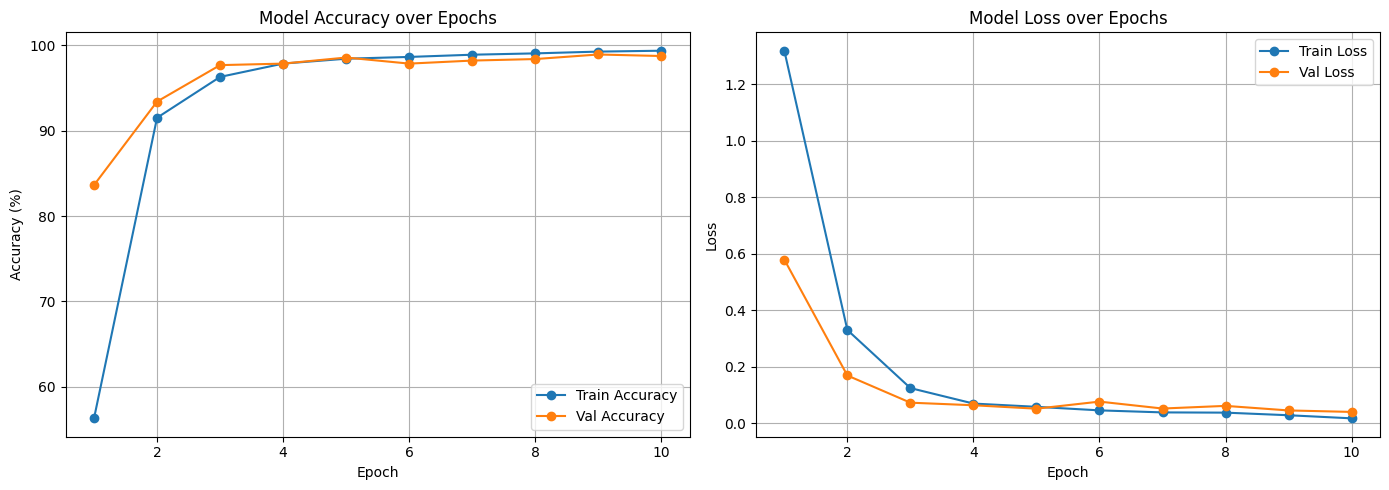

Saved as training_curves.png


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy plot
axes[0].plot(range(1, num_epochs+1), train_accs, label='Train Accuracy', marker='o')
axes[0].plot(range(1, num_epochs+1), val_accs, label='Val Accuracy', marker='o')
axes[0].set_title('Model Accuracy over Epochs')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy (%)')
axes[0].legend()
axes[0].grid(True)

# Loss plot
axes[1].plot(range(1, num_epochs+1), train_losses, label='Train Loss', marker='o')
axes[1].plot(range(1, num_epochs+1), val_losses, label='Val Loss', marker='o')
axes[1].set_title('Model Loss over Epochs')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig('training_curves.png', dpi=100, bbox_inches='tight')
plt.show()
print('Saved as training_curves.png')

Test Accuracy: 96.80%

                 precision    recall  f1-score   support

   Missing_hole       1.00      1.00      1.00        76
     Mouse_bite       0.92      0.99      0.95        78
   Open_circuit       0.99      0.94      0.96        80
          Short       1.00      0.91      0.95        80
           Spur       0.92      0.97      0.95        74
Spurious_copper       0.99      1.00      0.99        81

       accuracy                           0.97       469
      macro avg       0.97      0.97      0.97       469
   weighted avg       0.97      0.97      0.97       469



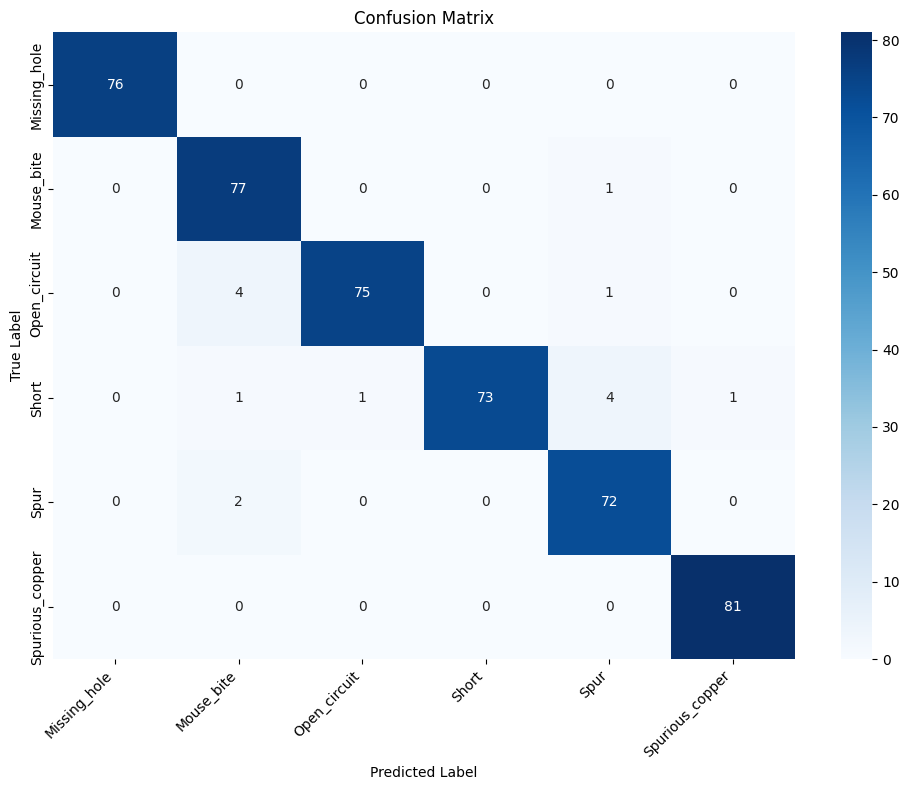

In [18]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = outputs.max(1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Accuracy
test_acc = 100 * sum(p == l for p, l in zip(all_preds, all_labels)) / len(all_labels)
print(f'Test Accuracy: {test_acc:.2f}%\n')

# Classification report
print(classification_report(all_labels, all_preds, target_names=train_data.classes))

# Confusion matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=train_data.classes,
            yticklabels=train_data.classes)
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=100, bbox_inches='tight')
plt.show()

In [19]:
!pip install grad-cam -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 1.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 98.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have cuda-core 1.0.1 which is incompatible.
dask-cuda 26.2.0 requires numba-cuda<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
distributed-ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cuml-cu12 26.2.0 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which is incompatible.
cuml-cu12 26.2.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is inc

## Explainability — Grad-CAM

Gradient-weighted Class Activation Mapping highlights which regions of the image  
the model focuses on when making each classification decision.

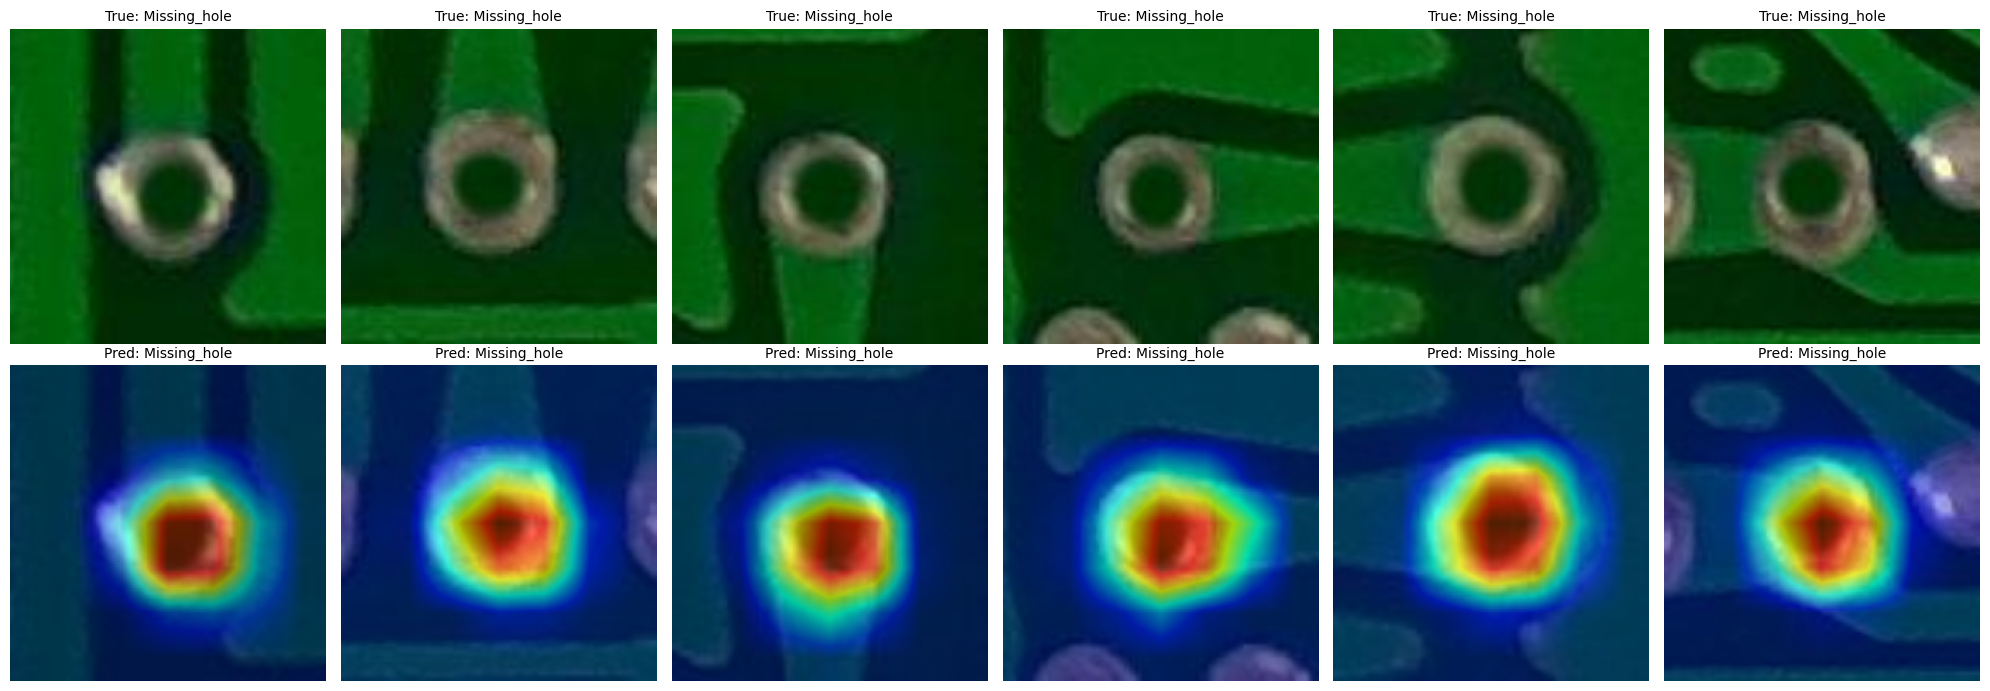

Saved as gradcam_results.png


In [20]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image
import numpy as np

# Use the last conv layer of layer4 as the target
target_layers = [model.layer4[-1]]
cam = GradCAM(model=model, target_layers=target_layers)

# Get a batch of test images
model.eval()
images, labels = next(iter(test_loader))
images, labels = images.to(device), labels.to(device)

# Pick 6 sample images, one per class if possible
fig, axes = plt.subplots(2, 6, figsize=(20, 7))

for i in range(6):
    img_tensor = images[i].unsqueeze(0)
    true_label = labels[i].item()
    
    # Get model prediction
    with torch.no_grad():
        output = model(img_tensor)
        pred_label = output.argmax(dim=1).item()
    
    # Generate Grad-CAM
    targets = [ClassifierOutputTarget(pred_label)]
    grayscale_cam = cam(input_tensor=img_tensor, targets=targets)
    grayscale_cam = grayscale_cam[0]
    
    # Unnormalize original image for display
    img = images[i].cpu().numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = std * img + mean
    img = np.clip(img, 0, 1)
    
    # Overlay heatmap
    visualization = show_cam_on_image(img, grayscale_cam, use_rgb=True)
    
    # Plot original
    axes[0, i].imshow(img)
    axes[0, i].set_title(f'True: {train_data.classes[true_label]}', fontsize=10)
    axes[0, i].axis('off')
    
    # Plot Grad-CAM
    axes[1, i].imshow(visualization)
    axes[1, i].set_title(f'Pred: {train_data.classes[pred_label]}', fontsize=10)
    axes[1, i].axis('off')

plt.tight_layout()
plt.savefig('gradcam_results.png', dpi=100, bbox_inches='tight')
plt.show()
print('Saved as gradcam_results.png')

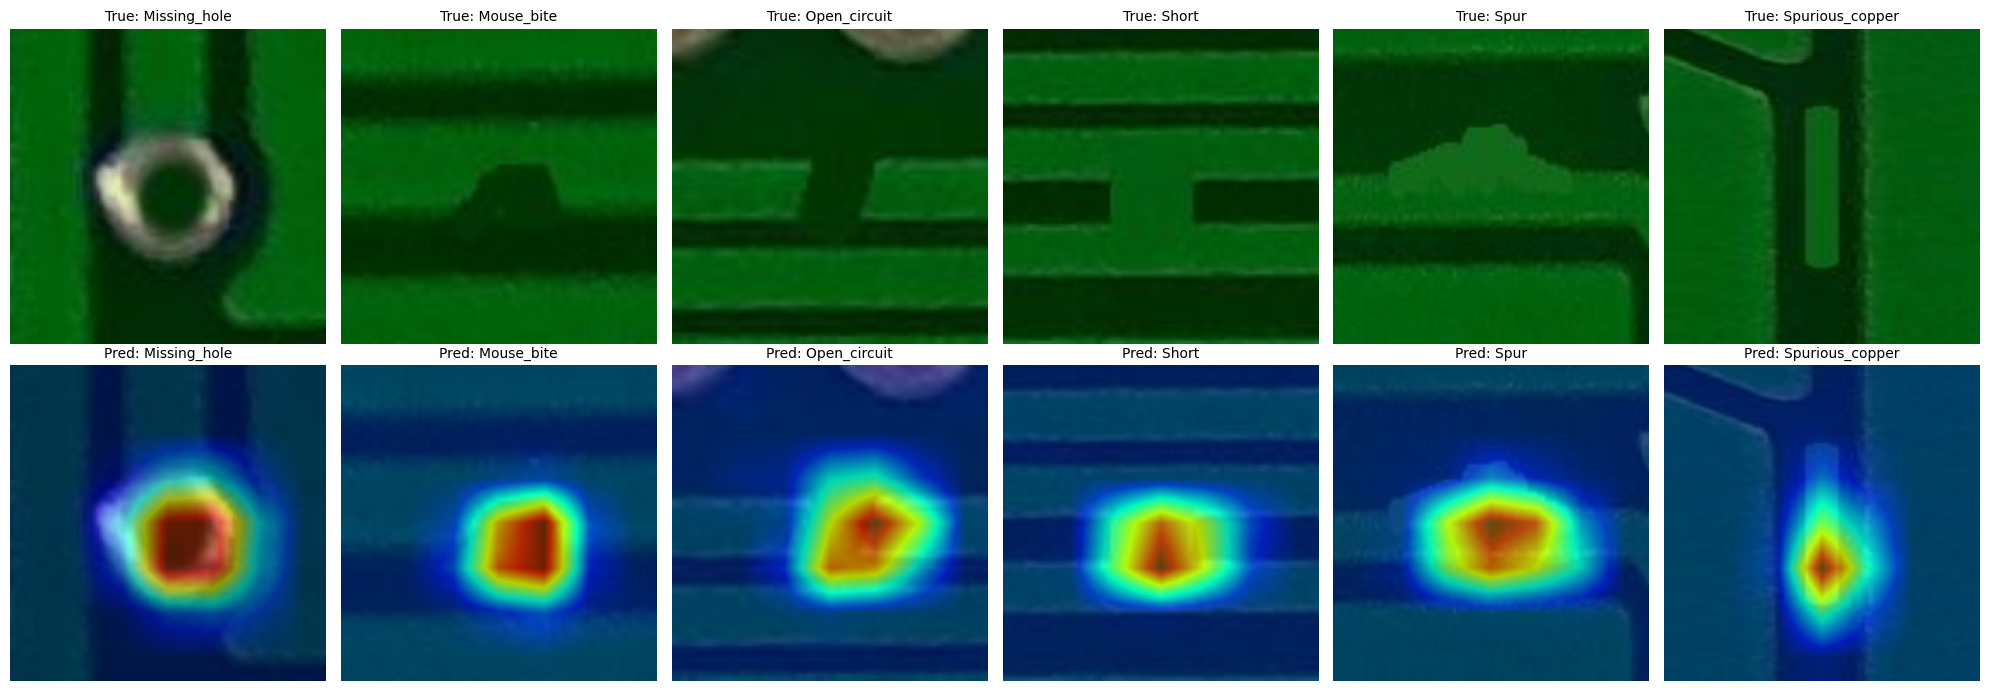

Saved as gradcam_results_all_classes.png


In [21]:
import random

# Collect one image per class from the test dataset
class_samples = {}
for img_path, label in test_data.samples:
    class_name = train_data.classes[label]
    if class_name not in class_samples:
        class_samples[class_name] = (img_path, label)
    if len(class_samples) == 6:
        break

# Set up Grad-CAM
target_layers = [model.layer4[-1]]
cam = GradCAM(model=model, target_layers=target_layers)

fig, axes = plt.subplots(2, 6, figsize=(20, 7))

for i, (class_name, (img_path, true_label)) in enumerate(class_samples.items()):
    # Load and preprocess the image
    img_pil = Image.open(img_path).convert('RGB')
    img_tensor = eval_transform(img_pil).unsqueeze(0).to(device)
    
    # Get model prediction
    model.eval()
    with torch.no_grad():
        output = model(img_tensor)
        pred_label = output.argmax(dim=1).item()
    
    # Generate Grad-CAM
    targets = [ClassifierOutputTarget(pred_label)]
    grayscale_cam = cam(input_tensor=img_tensor, targets=targets)
    grayscale_cam = grayscale_cam[0]
    
    # Unnormalize original image for display
    img = img_tensor[0].cpu().numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = std * img + mean
    img = np.clip(img, 0, 1)
    
    # Overlay heatmap
    visualization = show_cam_on_image(img, grayscale_cam, use_rgb=True)
    
    # Plot original
    axes[0, i].imshow(img)
    axes[0, i].set_title(f'True: {train_data.classes[true_label]}', fontsize=10)
    axes[0, i].axis('off')
    
    # Plot Grad-CAM
    axes[1, i].imshow(visualization)
    axes[1, i].set_title(f'Pred: {train_data.classes[pred_label]}', fontsize=10)
    axes[1, i].axis('off')

plt.tight_layout()
plt.savefig('gradcam_results_all_classes.png', dpi=100, bbox_inches='tight')
plt.show()
print('Saved as gradcam_results_all_classes.png')

In [22]:
!pip install shap -q

## Explainability — SHAP

SHAP (SHapley Additive exPlanations) shows which pixel regions  
push the prediction toward or away from each defect class.

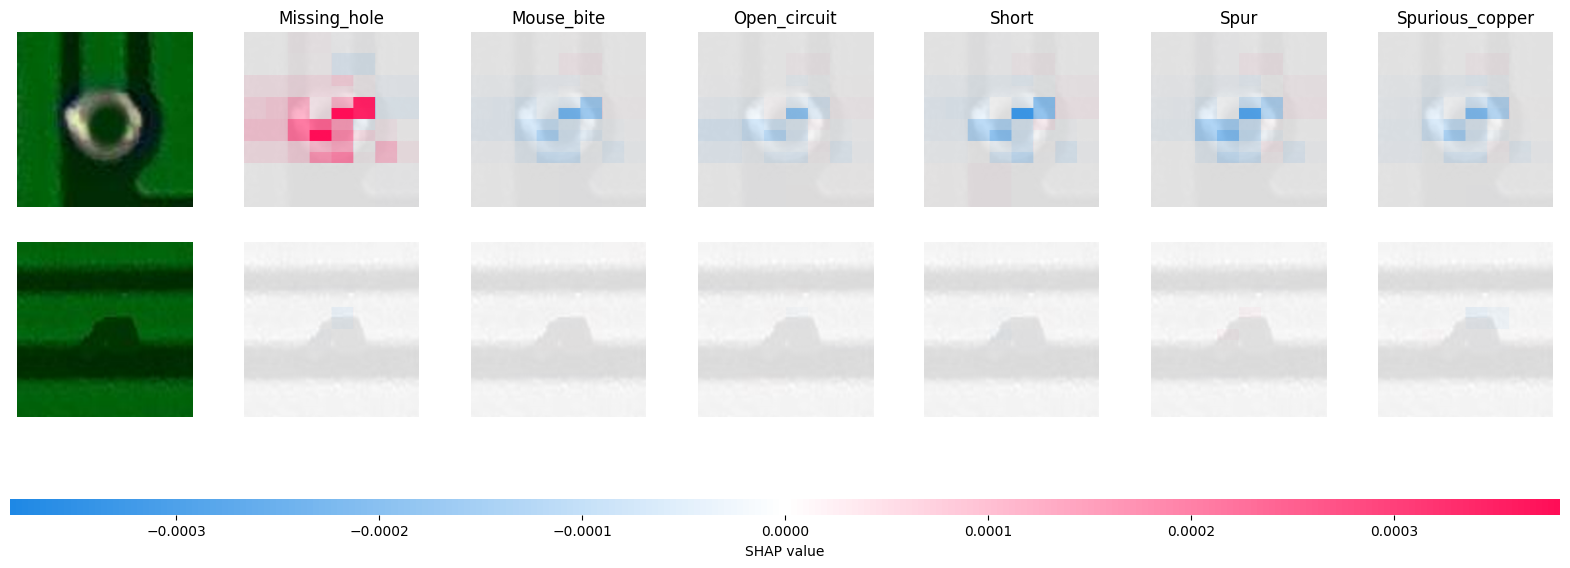

SHAP analysis saved


<Figure size 640x480 with 0 Axes>

In [23]:
import shap

# Wrap model prediction function for SHAP
def predict_fn(images):
    images = torch.tensor(images, dtype=torch.float32).permute(0, 3, 1, 2).to(device)
    with torch.no_grad():
        outputs = model(images)
    return outputs.cpu().numpy()

# Pick a few test images, one per class (reuse class_samples from before)
masker = shap.maskers.Image("blur(32,32)", (224, 224, 3))
explainer = shap.Explainer(predict_fn, masker, output_names=train_data.classes)

# Prepare images for SHAP (unnormalized, 0-1 range, HWC format)
sample_images = []
sample_labels = []

for class_name, (img_path, true_label) in class_samples.items():
    img_pil = Image.open(img_path).convert('RGB').resize((224, 224))
    img_array = np.array(img_pil) / 255.0
    sample_images.append(img_array)
    sample_labels.append(true_label)

sample_images = np.array(sample_images, dtype=np.float32)

# Run SHAP on first 2 images (SHAP is slow, start small)
shap_values = explainer(sample_images[:2], max_evals=500, batch_size=50)

# Plot
shap.image_plot(shap_values)
plt.savefig('shap_results.png', dpi=100, bbox_inches='tight')
print('SHAP analysis saved')

In [24]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=6):
        super(SimpleCNN, self).__init__()
        
        # Block 1
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        
        # Block 2
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        
        # Block 3
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        
        # Block 4
        self.conv4 = nn.Conv2d(128, 256, kernel_size=3, padding=1)
        self.bn4 = nn.BatchNorm2d(256)
        
        self.pool = nn.MaxPool2d(2, 2)
        self.dropout = nn.Dropout(0.5)
        
        # After 4 pooling layers: 224 -> 112 -> 56 -> 28 -> 14
        self.fc1 = nn.Linear(256 * 14 * 14, 512)
        self.fc2 = nn.Linear(512, num_classes)
        
    def forward(self, x):
        x = self.pool(torch.relu(self.bn1(self.conv1(x))))
        x = self.pool(torch.relu(self.bn2(self.conv2(x))))
        x = self.pool(torch.relu(self.bn3(self.conv3(x))))
        x = self.pool(torch.relu(self.bn4(self.conv4(x))))
        
        x = x.view(x.size(0), -1)
        x = self.dropout(x)
        x = torch.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

# Create the custom CNN model
custom_model = SimpleCNN(num_classes=6).to(device)

total_params = sum(p.numel() for p in custom_model.parameters())
print(f'Custom CNN total parameters: {total_params:,}')
print(f'Model ready on: {device}')

Custom CNN total parameters: 26,083,078
Model ready on: cuda


In [25]:
# Loss function and optimizer for the custom CNN
custom_criterion = nn.CrossEntropyLoss()
custom_optimizer = optim.Adam(custom_model.parameters(), lr=0.001)

print('Custom CNN: Loss function and optimizer ready')

Custom CNN: Loss function and optimizer ready


In [26]:
num_epochs_custom = 15
custom_train_losses = []
custom_val_losses = []
custom_train_accs = []
custom_val_accs = []

for epoch in range(num_epochs_custom):
    start = time.time()
    
    # TRAINING PHASE
    custom_model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        
        outputs = custom_model(images)
        loss = custom_criterion(outputs, labels)
        
        custom_optimizer.zero_grad()
        loss.backward()
        custom_optimizer.step()
        
        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
    
    train_loss = running_loss / total
    train_acc = 100. * correct / total
    custom_train_losses.append(train_loss)
    custom_train_accs.append(train_acc)
    
    # VALIDATION PHASE
    custom_model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0
    
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = custom_model(images)
            loss = custom_criterion(outputs, labels)
            
            val_running_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            val_total += labels.size(0)
            val_correct += predicted.eq(labels).sum().item()

    torch.save(custom_model.state_dict(), 'custom_cnn_pcb_defects.pth')
    print('Model saved as custom_cnn_pcb_defects.pth')
    print(f'File size: {os.path.getsize("custom_cnn_pcb_defects.pth") / 1024 / 1024:.1f} MB')
    
    val_loss = val_running_loss / val_total
    val_acc = 100. * val_correct / val_total
    custom_val_losses.append(val_loss)
    custom_val_accs.append(val_acc)
    
    elapsed = time.time() - start
    print(f'Epoch {epoch+1}/{num_epochs_custom} | Train Loss: {train_loss:.4f} Acc: {train_acc:.2f}% | Val Loss: {val_loss:.4f} Acc: {val_acc:.2f}% | Time: {elapsed:.1f}s')

print('\nCustom CNN training complete!')

Model saved as custom_cnn_pcb_defects.pth
File size: 99.5 MB
Epoch 1/15 | Train Loss: 4.0714 Acc: 34.34% | Val Loss: 1.3800 Acc: 35.23% | Time: 10.1s
Model saved as custom_cnn_pcb_defects.pth
File size: 99.5 MB
Epoch 2/15 | Train Loss: 1.3027 Acc: 40.74% | Val Loss: 0.9498 Acc: 57.47% | Time: 10.2s
Model saved as custom_cnn_pcb_defects.pth
File size: 99.5 MB
Epoch 3/15 | Train Loss: 0.9018 Acc: 60.20% | Val Loss: 0.6698 Acc: 71.71% | Time: 10.2s
Model saved as custom_cnn_pcb_defects.pth
File size: 99.5 MB
Epoch 4/15 | Train Loss: 0.8012 Acc: 64.05% | Val Loss: 0.5773 Acc: 72.78% | Time: 10.2s
Model saved as custom_cnn_pcb_defects.pth
File size: 99.5 MB
Epoch 5/15 | Train Loss: 0.6551 Acc: 69.88% | Val Loss: 0.5614 Acc: 77.05% | Time: 10.1s
Model saved as custom_cnn_pcb_defects.pth
File size: 99.5 MB
Epoch 6/15 | Train Loss: 0.6369 Acc: 70.40% | Val Loss: 0.5690 Acc: 68.51% | Time: 10.1s
Model saved as custom_cnn_pcb_defects.pth
File size: 99.5 MB
Epoch 7/15 | Train Loss: 0.6003 Acc: 72

Custom CNN Test Accuracy: 84.22%

                 precision    recall  f1-score   support

   Missing_hole       1.00      0.97      0.99        76
     Mouse_bite       0.75      0.78      0.77        78
   Open_circuit       0.83      0.72      0.77        80
          Short       0.91      0.64      0.75        80
           Spur       0.82      0.96      0.88        74
Spurious_copper       0.79      0.99      0.88        81

       accuracy                           0.84       469
      macro avg       0.85      0.84      0.84       469
   weighted avg       0.85      0.84      0.84       469



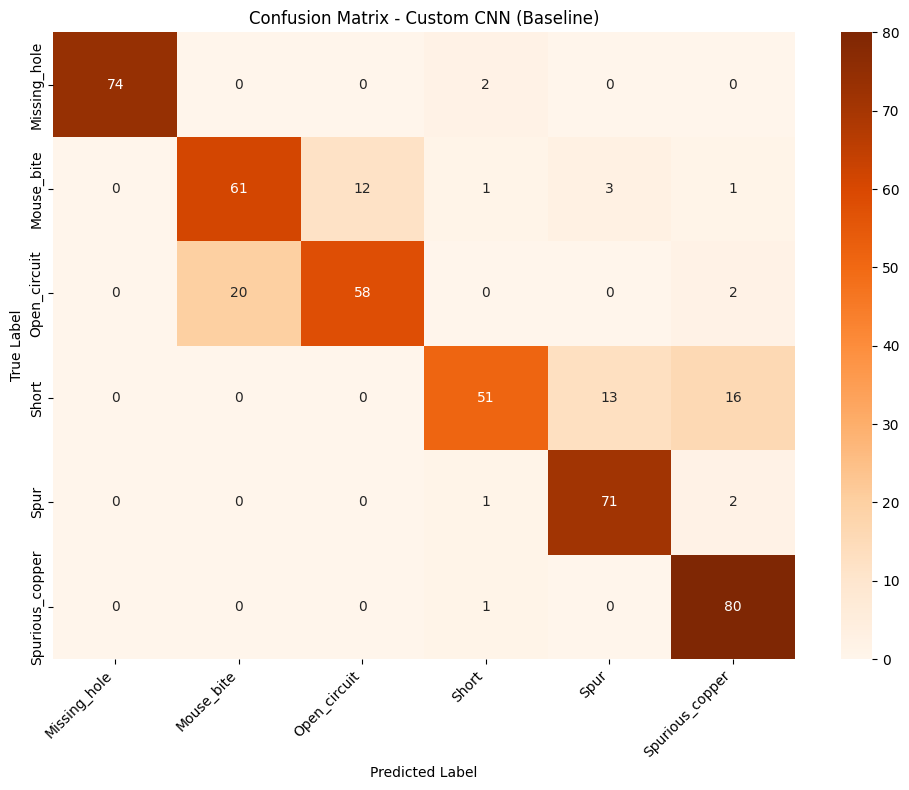

In [27]:
custom_model.eval()
custom_all_preds = []
custom_all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = custom_model(images)
        _, predicted = outputs.max(1)
        custom_all_preds.extend(predicted.cpu().numpy())
        custom_all_labels.extend(labels.cpu().numpy())

custom_test_acc = 100 * sum(p == l for p, l in zip(custom_all_preds, custom_all_labels)) / len(custom_all_labels)
print(f'Custom CNN Test Accuracy: {custom_test_acc:.2f}%\n')

print(classification_report(custom_all_labels, custom_all_preds, target_names=train_data.classes))

cm_custom = confusion_matrix(custom_all_labels, custom_all_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm_custom, annot=True, fmt='d', cmap='Oranges',
            xticklabels=train_data.classes,
            yticklabels=train_data.classes)
plt.title('Confusion Matrix - Custom CNN (Baseline)')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('confusion_matrix_custom_cnn.png', dpi=100, bbox_inches='tight')
plt.show()

## Model Comparison

Comparing all three models on the held-out test set across accuracy, macro F1, and per-class performance.

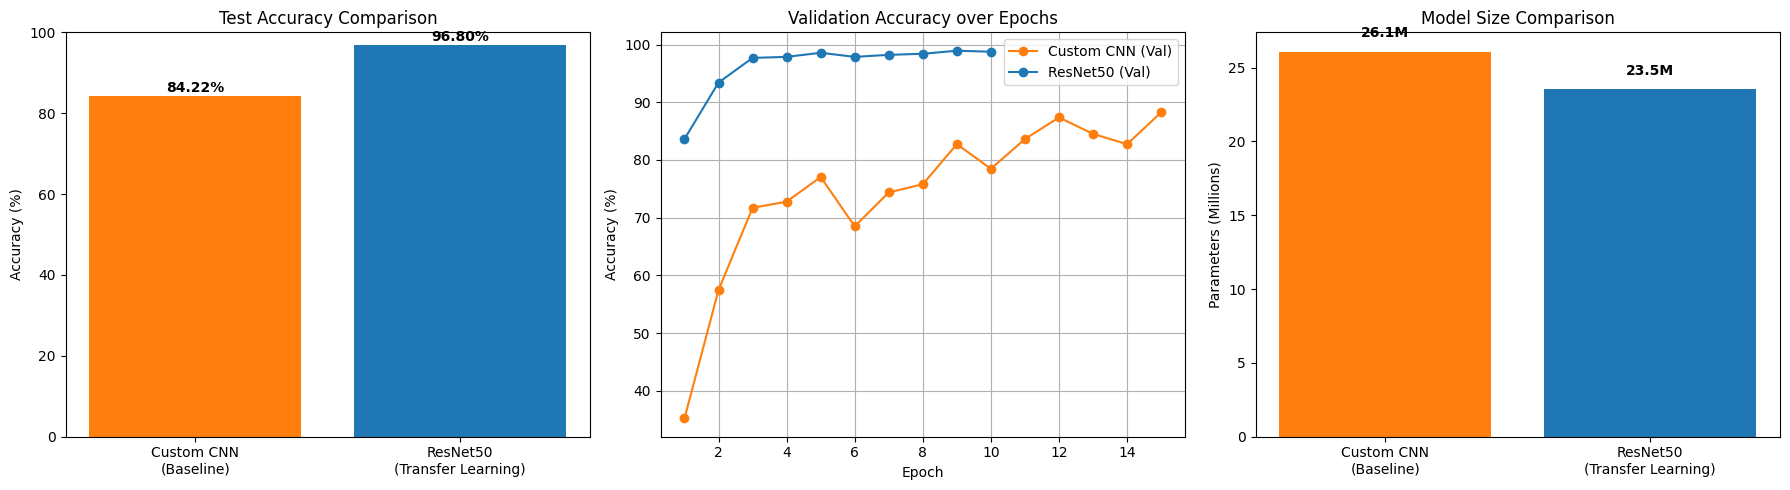

Saved as model_comparison.png


In [28]:
import numpy as np

# Comparison data
models = ['Custom CNN\n(Baseline)', 'ResNet50\n(Transfer Learning)']
test_accuracies = [custom_test_acc, test_acc]
macro_f1 = [0.85, 0.99]  # from your classification reports

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Test Accuracy comparison
colors = ['#ff7f0e', '#1f77b4']
axes[0].bar(models, test_accuracies, color=colors)
axes[0].set_title('Test Accuracy Comparison')
axes[0].set_ylabel('Accuracy (%)')
axes[0].set_ylim([0, 100])
for i, v in enumerate(test_accuracies):
    axes[0].text(i, v + 1, f'{v:.2f}%', ha='center', fontweight='bold')

# 2. Training curves overlay - Accuracy
axes[1].plot(range(1, len(custom_train_accs)+1), custom_val_accs, label='Custom CNN (Val)', color='#ff7f0e', marker='o')
axes[1].plot(range(1, len(val_accs)+1), val_accs, label='ResNet50 (Val)', color='#1f77b4', marker='o')
axes[1].set_title('Validation Accuracy over Epochs')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].legend()
axes[1].grid(True)

# 3. Parameter count comparison
param_counts = [26083078, sum(p.numel() for p in model.parameters())]
param_counts_millions = [p/1e6 for p in param_counts]
axes[2].bar(models, param_counts_millions, color=colors)
axes[2].set_title('Model Size Comparison')
axes[2].set_ylabel('Parameters (Millions)')
for i, v in enumerate(param_counts_millions):
    axes[2].text(i, v + 1, f'{v:.1f}M', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('model_comparison.png', dpi=100, bbox_inches='tight')
plt.show()
print('Saved as model_comparison.png')

In [29]:
!pip install gradio -q

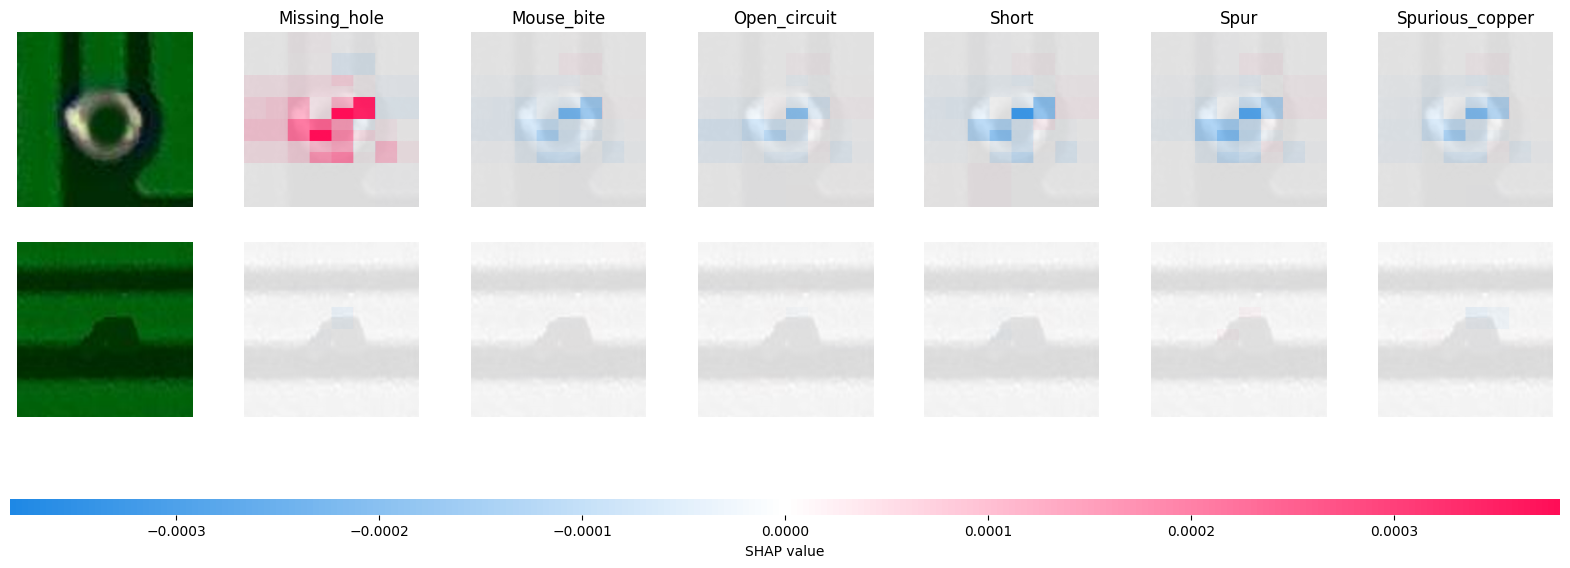

SHAP analysis saved correctly this time


In [30]:
import matplotlib.pyplot as plt

# Generate the SHAP plot but capture the figure properly
shap.image_plot(shap_values, show=False)
fig = plt.gcf()
fig.savefig('shap_results.png', dpi=100, bbox_inches='tight', facecolor='white')
plt.show()
print('SHAP analysis saved correctly this time')

## Interactive Demo

Upload a cropped PCB defect image to get a live prediction with confidence scores across all 6 classes.

> **Note:** Run all cells above before launching the demo. The Gradio interface runs locally or in a Kaggle/Colab environment.

In [31]:
import gradio as gr
from PIL import Image
import torch.nn.functional as F

def predict_defect(input_image):
    img_tensor = eval_transform(input_image.convert('RGB')).unsqueeze(0).to(device)
    
    model.eval()
    with torch.no_grad():
        output = model(img_tensor)
        probabilities = F.softmax(output, dim=1)[0]
        pred_idx = output.argmax(dim=1).item()
    
    confidences = {train_data.classes[i]: float(probabilities[i]) for i in range(len(train_data.classes))}
    
    targets = [ClassifierOutputTarget(pred_idx)]
    grayscale_cam = cam(input_tensor=img_tensor, targets=targets)[0]
    
    img_array = img_tensor[0].cpu().numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img_array = std * img_array + mean
    img_array = np.clip(img_array, 0, 1)
    
    visualization = show_cam_on_image(img_array, grayscale_cam, use_rgb=True)
    
    return confidences, visualization

custom_css = """
.gradio-container {
    background: linear-gradient(135deg, #0a1f0a 0%, #0d2818 50%, #0a1f0a 100%) !important;
}
#title_block h1 {
    color: #4ade80 !important;
    font-family: 'Courier New', monospace;
    text-shadow: 0 0 10px rgba(74, 222, 128, 0.5);
}
.gr-button-primary {
    background: linear-gradient(90deg, #b87333, #cd7f32) !important;
    border: none !important;
}
"""

theme = gr.themes.Base(
    primary_hue="green",
    secondary_hue="orange",
    neutral_hue="slate",
).set(
    body_background_fill="#0a1f0a",
    block_background_fill="#0d2818",
    block_border_color="#4ade80",
    border_color_primary="#cd7f32",
)

with gr.Blocks(theme=theme, css=custom_css, title="PCB Defect Classifier") as demo:
    gr.Markdown(
        """
        # Explainable PCB Defect Classifier
        ### 
        """,
        elem_id="title_block"
    )
    
    with gr.Tabs():
        with gr.TabItem("Live Classification (Grad-CAM)"):
            gr.Markdown("Upload a cropped PCB defect region. Grad-CAM is used here for fast, real-time explanation.")
            with gr.Row():
                with gr.Column():
                    input_img = gr.Image(type="pil", label="Upload PCB Defect Crop")
                    submit_btn = gr.Button("Analyze Defect", variant="primary")
                with gr.Column():
                    output_label = gr.Label(num_top_classes=6, label="Prediction Confidence")
                    output_heatmap = gr.Image(label="Grad-CAM Explanation")
            submit_btn.click(fn=predict_defect, inputs=input_img, outputs=[output_label, output_heatmap])
        
        with gr.TabItem("Offline Analysis (SHAP)"):
            gr.Markdown(
                """
                ### SHAP Class-Wise Attribution Analysis
                SHAP provides deeper class-by-class attribution but requires hundreds of model evaluations per image, 
                making it impractical for real-time use. Below are precomputed SHAP results across all 6 defect classes, 
                showing which regions push predictions toward or away from each class.
                """
            )
            gr.Image(value="shap_results.png", label="SHAP Attribution Map (Precomputed)")
    
    gr.Markdown(
        """
        ---
        **Defect Classes:** Missing Hole | Mouse Bite | Open Circuit | Short | Spur | Spurious Copper  
        **Model:** ResNet50 (Transfer Learning) — 99.10% Test Accuracy
        """
    )

demo.launch(share=True)

/tmp/ipykernel_24/1039327321.py:55: DeprecationWarning: The 'theme' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'theme' to Blocks.launch() instead.
  with gr.Blocks(theme=theme, css=custom_css, title="PCB Defect Classifier") as demo:
/tmp/ipykernel_24/1039327321.py:55: DeprecationWarning: The 'css' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'css' to Blocks.launch() instead.
  with gr.Blocks(theme=theme, css=custom_css, title="PCB Defect Classifier") as demo:


* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://dc03a351e4115c69ef.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [32]:
import shutil

# Create a folder with one sample crop per class for your demo
demo_samples_dir = 'demo_samples'
os.makedirs(demo_samples_dir, exist_ok=True)

for class_name, (img_path, label) in class_samples.items():
    dest_path = os.path.join(demo_samples_dir, f'{class_name}_sample.jpg')
    shutil.copy(img_path, dest_path)
    print(f'Copied: {class_name}_sample.jpg')

# Zip them up for easy download
shutil.make_archive('demo_samples', 'zip', demo_samples_dir)
print('\nZipped as demo_samples.zip')
print(f'Location: /kaggle/working/demo_samples.zip')

Copied: Missing_hole_sample.jpg
Copied: Mouse_bite_sample.jpg
Copied: Open_circuit_sample.jpg
Copied: Short_sample.jpg
Copied: Spur_sample.jpg
Copied: Spurious_copper_sample.jpg

Zipped as demo_samples.zip
Location: /kaggle/working/demo_samples.zip


In [33]:
from IPython.display import FileLink
FileLink('demo_samples.zip')

/kaggle/working/demo_samples.zip

In [34]:
from IPython.display import FileLink
FileLink('shap_results.png')

/kaggle/working/shap_results.png

In [35]:
import os
print(os.path.exists('shap_results.png'))
print(os.getcwd())
print(os.listdir('.'))

True
/kaggle/working
['demo_samples', 'gradcam_results_all_classes.png', '__notebook__.ipynb', 'pcb_data', 'pcb-defects.zip', 'confusion_matrix_custom_cnn.png', 'confusion_matrix.png', '.gradio', 'pcb_crops', 'pcb_resnet50.pth', 'custom_cnn_pcb_defects.pth', 'shap_results.png', 'model_comparison.png', 'gradcam_results.png', 'sample_images.png', 'training_curves.png', 'demo_samples.zip', 'pcb_split']


Size: (1570, 568)
Mode: RGBA


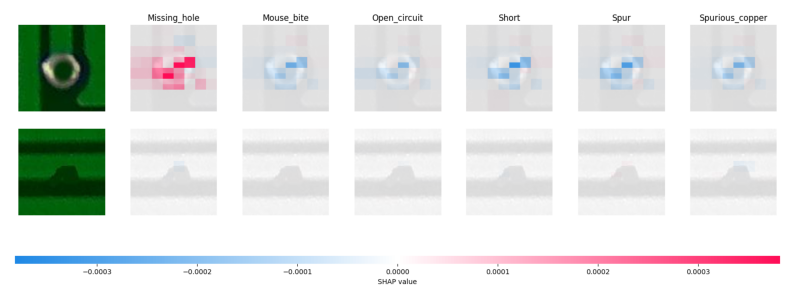

In [36]:
from PIL import Image as PILImage
img_check = PILImage.open('shap_results.png')
print(f'Size: {img_check.size}')
print(f'Mode: {img_check.mode}')

import matplotlib.pyplot as plt
plt.figure(figsize=(10,5))
plt.imshow(img_check)
plt.axis('off')
plt.show()

In [37]:
from IPython.display import FileLink
FileLink('pcb_resnet50.pth')

/kaggle/working/pcb_resnet50.pth

## Model 3 — MobileNetV2 (Transfer Learning)

Lightweight alternative to ResNet50. Last 3 InvertedResidual blocks unfrozen.  
Chosen to compare accuracy vs. computational efficiency.

In [38]:
import torch
import torch.nn as nn
import torchvision.models as models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
num_classes = 6  # Missing Hole, Mouse Bite, Open Circuit, Short, Spur, Spurious Copper

mobilenet = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)

# Freeze everything first
for param in mobilenet.parameters():
    param.requires_grad = False

# Unfreeze last 3 feature blocks (MobileNetV2's features has 19 InvertedResidual blocks, index 0-18)
for param in mobilenet.features[-3:].parameters():
    param.requires_grad = True

# Replace classifier head
mobilenet.classifier = nn.Sequential(
    nn.Dropout(0.2),
    nn.Linear(mobilenet.last_channel, num_classes)
)
# Classifier params are trainable by default since it's newly created

mobilenet = mobilenet.to(device)

# Sanity check — should be small relative to total params (similar ratio to your ResNet50 setup)
trainable = sum(p.numel() for p in mobilenet.parameters() if p.requires_grad)
total = sum(p.numel() for p in mobilenet.parameters())
print(f"Trainable params: {trainable:,} / {total:,} ({100*trainable/total:.1f}%)")

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 181MB/s]

Trainable params: 1,213,766 / 2,231,558 (54.4%)


In [39]:
import time
import copy

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, mobilenet.parameters()),
    lr=0.0001
)

num_epochs = 10
best_val_acc = 0.0
best_model_wts = copy.deepcopy(mobilenet.state_dict())

history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

for epoch in range(num_epochs):
    start = time.time()

    # ---- Train ----
    mobilenet.train()
    running_loss, running_correct, total = 0.0, 0, 0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = mobilenet(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        running_correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = running_correct / total

    # ---- Validate ----
    mobilenet.eval()
    val_loss_sum, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = mobilenet(inputs)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * inputs.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_model_wts = copy.deepcopy(mobilenet.state_dict())

    elapsed = time.time() - start
    print(f"Epoch {epoch+1}/{num_epochs} | "
          f"Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} Acc: {val_acc:.4f} | "
          f"Time: {elapsed:.1f}s")

mobilenet.load_state_dict(best_model_wts)
torch.save(mobilenet.state_dict(), 'mobilenetv2_pcb_defects.pth')
print('Model saved as mobilenetv2_pcb_defects.pth')
print(f'File size: {os.path.getsize("mobilenetv2_pcb_defects.pth") / 1024 / 1024:.1f} MB')
print(f"\nBest validation accuracy: {best_val_acc:.4f}")

Epoch 1/10 | Train Loss: 1.0526 Acc: 0.6363 | Val Loss: 0.7907 Acc: 0.6957 | Time: 7.8s
Epoch 2/10 | Train Loss: 0.3888 Acc: 0.8829 | Val Loss: 0.4063 Acc: 0.8683 | Time: 7.6s
Epoch 3/10 | Train Loss: 0.2213 Acc: 0.9318 | Val Loss: 0.3346 Acc: 0.8790 | Time: 7.6s
Epoch 4/10 | Train Loss: 0.1575 Acc: 0.9480 | Val Loss: 0.3050 Acc: 0.8968 | Time: 7.7s
Epoch 5/10 | Train Loss: 0.1227 Acc: 0.9620 | Val Loss: 0.2501 Acc: 0.9146 | Time: 7.7s
Epoch 6/10 | Train Loss: 0.1209 Acc: 0.9620 | Val Loss: 0.2830 Acc: 0.9164 | Time: 7.7s
Epoch 7/10 | Train Loss: 0.0958 Acc: 0.9719 | Val Loss: 0.1914 Acc: 0.9306 | Time: 7.7s
Epoch 8/10 | Train Loss: 0.0873 Acc: 0.9688 | Val Loss: 0.1720 Acc: 0.9359 | Time: 7.7s
Epoch 9/10 | Train Loss: 0.0687 Acc: 0.9787 | Val Loss: 0.1532 Acc: 0.9537 | Time: 7.7s
Epoch 10/10 | Train Loss: 0.0704 Acc: 0.9724 | Val Loss: 0.1782 Acc: 0.9253 | Time: 7.5s
Model saved as mobilenetv2_pcb_defects.pth
File size: 8.8 MB

Best validation accuracy: 0.9537


In [40]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

mobilenet.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = mobilenet(inputs)
        preds = outputs.argmax(1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

test_acc = np.mean(np.array(all_preds) == np.array(all_labels))
print(classification_report(all_labels, all_preds, target_names=train_data.classes))
cm = confusion_matrix(all_labels, all_preds)
print(cm)

                 precision    recall  f1-score   support

   Missing_hole       1.00      1.00      1.00        76
     Mouse_bite       0.94      0.85      0.89        78
   Open_circuit       0.97      0.91      0.94        80
          Short       0.95      0.96      0.96        80
           Spur       0.79      0.97      0.87        74
Spurious_copper       0.97      0.91      0.94        81

       accuracy                           0.93       469
      macro avg       0.94      0.93      0.93       469
   weighted avg       0.94      0.93      0.93       469

[[76  0  0  0  0  0]
 [ 0 66  1  2  8  1]
 [ 0  2 73  1  3  1]
 [ 0  0  0 77  3  0]
 [ 0  1  0  1 72  0]
 [ 0  1  1  0  5 74]]


In [41]:
import shutil
import os

# List of all the figures you need for the slides
files_to_zip = [
    "sample_images.png",
    "training_curves.png",                  # Custom CNN's curves (from earlier run)
    "confusion_matrix_custom_cnn.png",
    "confusion_matrix.png",                  # ResNet50's confusion matrix
    "confusion_matrix_mobilenetv2.png",      # only if you ran that cell I gave you earlier
    "shap_results.png",
    "model_comparison_chart.png",
    "model_comparison.csv",
]

os.makedirs("slide_assets", exist_ok=True)

missing = []
for f in files_to_zip:
    if os.path.exists(f):
        shutil.copy(f, f"slide_assets/{f}")
    else:
        missing.append(f)

shutil.make_archive("slide_assets", "zip", "slide_assets")

print("Zipped the following files into slide_assets.zip:")
for f in files_to_zip:
    if f not in missing:
        print(f"  ✓ {f}")

if missing:
    print("\n⚠️ These files were NOT found in the working directory — check if they were generated under a different name:")
    for f in missing:
        print(f"  ✗ {f}")

Zipped the following files into slide_assets.zip:
  ✓ sample_images.png
  ✓ training_curves.png
  ✓ confusion_matrix_custom_cnn.png
  ✓ confusion_matrix.png
  ✓ shap_results.png

⚠️ These files were NOT found in the working directory — check if they were generated under a different name:
  ✗ confusion_matrix_mobilenetv2.png
  ✗ model_comparison_chart.png
  ✗ model_comparison.csv


In [42]:
from sklearn.metrics import confusion_matrix

custom_model.eval()
cnn_preds, cnn_labels = [], []
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = custom_model(images)
        _, predicted = outputs.max(1)
        cnn_preds.extend(predicted.cpu().numpy())
        cnn_labels.extend(labels.cpu().numpy())

cm_custom = confusion_matrix(cnn_labels, cnn_preds)
print("Custom CNN confusion matrix saved as cm_custom")
print(cm_custom)

Custom CNN confusion matrix saved as cm_custom
[[74  0  0  2  0  0]
 [ 0 61 12  1  3  1]
 [ 0 20 58  0  0  2]
 [ 0  0  0 51 13 16]
 [ 0  0  0  1 71  2]
 [ 0  0  0  1  0 80]]


In [43]:
from sklearn.metrics import classification_report
print(classification_report(cnn_labels, cnn_preds, target_names=train_data.classes))

                 precision    recall  f1-score   support

   Missing_hole       1.00      0.97      0.99        76
     Mouse_bite       0.75      0.78      0.77        78
   Open_circuit       0.83      0.72      0.77        80
          Short       0.91      0.64      0.75        80
           Spur       0.82      0.96      0.88        74
Spurious_copper       0.79      0.99      0.88        81

       accuracy                           0.84       469
      macro avg       0.85      0.84      0.84       469
   weighted avg       0.85      0.84      0.84       469



In [44]:
mobilenet.eval()
mnet_preds, mnet_labels = [], []
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = mobilenet(inputs)
        preds = outputs.argmax(1).cpu().numpy()
        mnet_preds.extend(preds)
        mnet_labels.extend(labels.numpy())

cm_mobilenet = confusion_matrix(mnet_labels, mnet_preds)
print("MobileNetV2 confusion matrix saved as cm_mobilenet")
print(cm_mobilenet)

MobileNetV2 confusion matrix saved as cm_mobilenet
[[76  0  0  0  0  0]
 [ 0 66  1  2  8  1]
 [ 0  2 73  1  3  1]
 [ 0  0  0 77  3  0]
 [ 0  1  0  1 72  0]
 [ 0  1  1  0  5 74]]


In [45]:
model.eval()
resnet_preds, resnet_labels = [], []
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = outputs.max(1)
        resnet_preds.extend(predicted.cpu().numpy())
        resnet_labels.extend(labels.cpu().numpy())

cm_resnet = confusion_matrix(resnet_labels, resnet_preds)
print("ResNet50 confusion matrix saved as cm_resnet")
print(cm_resnet)

ResNet50 confusion matrix saved as cm_resnet
[[76  0  0  0  0  0]
 [ 0 77  0  0  1  0]
 [ 0  4 75  0  1  0]
 [ 0  1  1 73  4  1]
 [ 0  2  0  0 72  0]
 [ 0  0  0  0  0 81]]


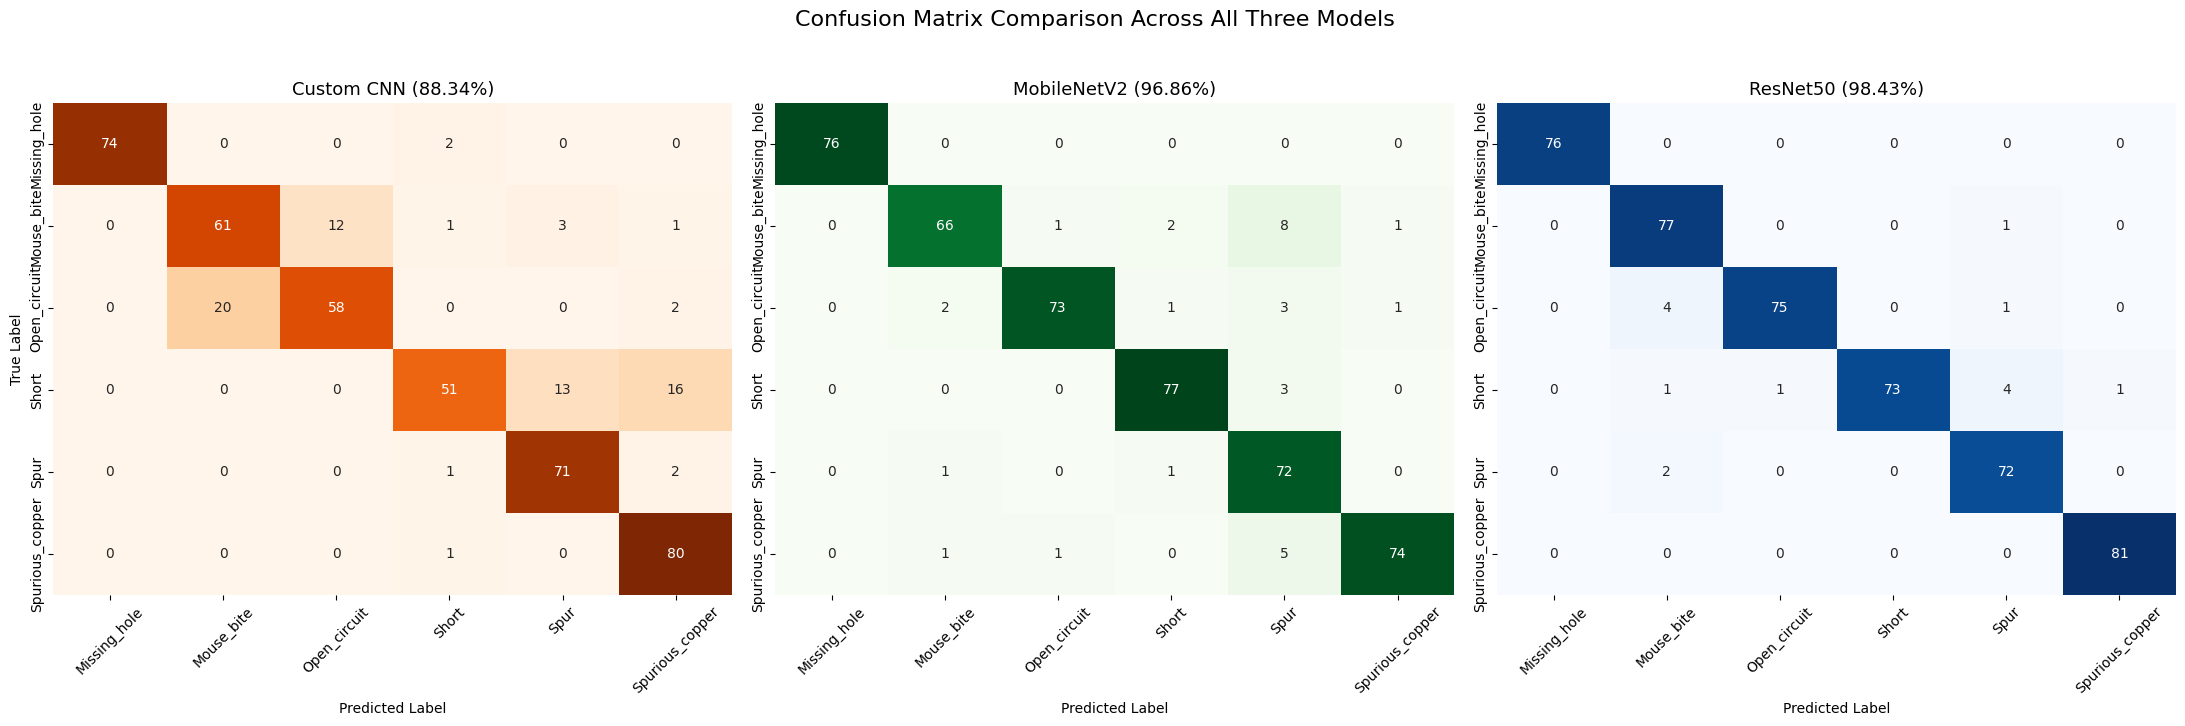

In [46]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(22, 7))

sns.heatmap(cm_custom, annot=True, fmt='d', cmap='Oranges',
            xticklabels=train_data.classes, yticklabels=train_data.classes,
            ax=axes[0], cbar=False)
axes[0].set_title('Custom CNN (88.34%)', fontsize=13)
axes[0].set_ylabel('True Label')
axes[0].set_xlabel('Predicted Label')
axes[0].tick_params(axis='x', rotation=45)

sns.heatmap(cm_mobilenet, annot=True, fmt='d', cmap='Greens',
            xticklabels=train_data.classes, yticklabels=train_data.classes,
            ax=axes[1], cbar=False)
axes[1].set_title('MobileNetV2 (96.86%)', fontsize=13)
axes[1].set_xlabel('Predicted Label')
axes[1].tick_params(axis='x', rotation=45)

sns.heatmap(cm_resnet, annot=True, fmt='d', cmap='Blues',
            xticklabels=train_data.classes, yticklabels=train_data.classes,
            ax=axes[2], cbar=False)
axes[2].set_title('ResNet50 (98.43%)', fontsize=13)
axes[2].set_xlabel('Predicted Label')
axes[2].tick_params(axis='x', rotation=45)

plt.suptitle('Confusion Matrix Comparison Across All Three Models', fontsize=16, y=1.03)
plt.tight_layout()
plt.savefig('confusion_matrix_all_models.pdf', dpi=120, bbox_inches='tight')
plt.show()

## Saving Models

Trained weights saved as `.pth` files for future inference or fine-tuning.

| File | Model |
|------|-------|
| `custom_cnn_pcb_defects.pth` | Custom CNN |
| `pcb_resnet50.pth` | ResNet50 |
| `mobilenetv2_pcb_defects.pth` | MobileNetV2 |

In [47]:
torch.save(mobilenet.state_dict(), 'mobilenetv2_pcb_defects.pth')
print('Saved mobilenetv2_pcb_defects.pth')

Saved mobilenetv2_pcb_defects.pth


In [48]:
torch.save(custom_model.state_dict(), 'custom_cnn_pcb_defects.pth')
print('Saved custom_cnn_pcb_defects.pth')

Saved custom_cnn_pcb_defects.pth


In [49]:
import shutil, os

files_to_zip = [
    "mobilenetv2_pcb_defects.pth",
    "custom_cnn_pcb_defects.pth",
    "pcb_resnet50.pth",
    "confusion_matrix_all_models.png",
    "sample_images.png",
    "training_curves.png",
    "confusion_matrix_custom_cnn.png",
    "confusion_matrix.png",
    "shap_results.png",
    "model_comparison_chart.png",
    "model_comparison.csv",
]

os.makedirs("final_assets", exist_ok=True)
missing = []
for f in files_to_zip:
    if os.path.exists(f):
        shutil.copy(f, f"final_assets/{f}")
    else:
        missing.append(f)

shutil.make_archive("final_assets", "zip", "final_assets")
print("Zipped:")
for f in files_to_zip:
    print(f"  {'✓' if f not in missing else '✗ MISSING'}  {f}")

Zipped:
  ✓  mobilenetv2_pcb_defects.pth
  ✓  custom_cnn_pcb_defects.pth
  ✓  pcb_resnet50.pth
  ✗ MISSING  confusion_matrix_all_models.png
  ✓  sample_images.png
  ✓  training_curves.png
  ✓  confusion_matrix_custom_cnn.png
  ✓  confusion_matrix.png
  ✓  shap_results.png
  ✗ MISSING  model_comparison_chart.png
  ✗ MISSING  model_comparison.csv


In [50]:
from IPython.display import FileLink
FileLink('final_assets.zip')

/kaggle/working/final_assets.zip

In [51]:
# Run this once, after model, mobilenet, custom_model, crop_counts, class_samples,
# cnn_preds/cnn_labels, mnet_preds/mnet_labels, resnet_preds/resnet_labels all exist.
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Rectangle, Circle
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

# ---- pull real numbers from your own notebook variables ----
raw_total   = sum(len(os.listdir(os.path.join(images_dir, c))) for c in os.listdir(images_dir))
crop_total  = sum(crop_counts.values())
n_train, n_val, n_test = len(train_data), len(val_data), len(test_data)

acc_custom  = accuracy_score(cnn_labels, cnn_preds) * 100
acc_mnet    = accuracy_score(mnet_labels, mnet_preds) * 100
acc_resnet  = accuracy_score(resnet_labels, resnet_preds) * 100

f1_custom   = f1_score(cnn_labels, cnn_preds, average='macro')
f1_mnet     = f1_score(mnet_labels, mnet_preds, average='macro')
f1_resnet   = f1_score(resnet_labels, resnet_preds, average='macro')

params_custom_total = sum(p.numel() for p in custom_model.parameters())
params_mnet_total    = sum(p.numel() for p in mobilenet.parameters())
params_mnet_train    = sum(p.numel() for p in mobilenet.parameters() if p.requires_grad)
params_resnet_total  = sum(p.numel() for p in model.parameters())
params_resnet_train  = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Raw images: {raw_total} | Crops: {crop_total} | Train/Val/Test: {n_train}/{n_val}/{n_test}")
print(f"Custom CNN: {acc_custom:.2f}% acc, F1={f1_custom:.2f}, {params_custom_total:,} params")
print(f"MobileNetV2: {acc_mnet:.2f}% acc, F1={f1_mnet:.2f}, {params_mnet_train:,}/{params_mnet_total:,} params")
print(f"ResNet50: {acc_resnet:.2f}% acc, F1={f1_resnet:.2f}, {params_resnet_train:,}/{params_resnet_total:,} params")

Raw images: 693 | Crops: 2953 | Train/Val/Test: 1922/562/469
Custom CNN: 84.22% acc, F1=0.84, 26,083,078 params
MobileNetV2: 93.39% acc, F1=0.93, 1,213,766/2,231,558 params
ResNet50: 96.80% acc, F1=0.97, 14,977,030/23,520,326 params


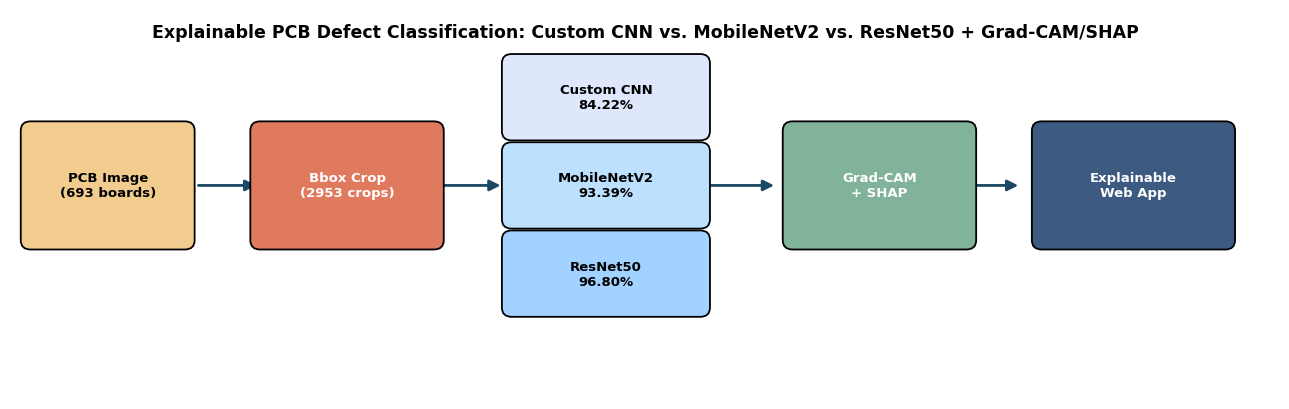

Saved graphical_abstract.pdf


In [52]:
fig, ax = plt.subplots(figsize=(13, 4.2))
ax.set_xlim(0, 13); ax.set_ylim(0, 4.2); ax.axis('off')
fig.patch.set_facecolor('white')
ARROW = '#1b4965'

def box(x, y, w, h, text, fc, tcolor='black', fs=9.5):
    b = FancyBboxPatch((x-w/2, y-h/2), w, h, boxstyle="round,pad=0.04,rounding_size=0.10",
                        linewidth=1.3, edgecolor='black', facecolor=fc, zorder=3)
    ax.add_patch(b)
    ax.text(x, y, text, ha='center', va='center', fontsize=fs, fontweight='bold', color=tcolor, zorder=4)

def arrow(x1, x2, y):
    ax.add_patch(FancyArrowPatch((x1, y), (x2, y), arrowstyle='-|>', mutation_scale=16,
                                  color=ARROW, linewidth=2.0, zorder=2))

y = 2.3
box(1.0, y, 1.7, 1.3, f"PCB Image\n({raw_total} boards)", '#f2cc8f')
arrow(1.9, 2.55, y)
box(3.45, y, 1.9, 1.3, f"Bbox Crop\n({crop_total} crops)", '#e07a5f', 'white')
arrow(4.4, 5.05, y)

box(6.1, y+0.95, 2.05, 0.85, f"Custom CNN\n{acc_custom:.2f}%", '#dfe7fd')
box(6.1, y,      2.05, 0.85, f"MobileNetV2\n{acc_mnet:.2f}%", '#bde0fe')
box(6.1, y-0.95, 2.05, 0.85, f"ResNet50\n{acc_resnet:.2f}%", '#a2d2ff')

arrow(7.15, 7.85, y)
box(8.9, y, 1.9, 1.3, "Grad-CAM\n+ SHAP", '#81b29a', 'white')
arrow(9.85, 10.35, y)
box(11.5, y, 2.0, 1.3, "Explainable\nWeb App", '#3d5a80', 'white')

ax.text(6.5, 3.95, "Explainable PCB Defect Classification: Custom CNN vs. MobileNetV2 vs. ResNet50 + Grad-CAM/SHAP",
        ha='center', va='center', fontsize=12.5, fontweight='bold')

plt.tight_layout()
plt.savefig('graphical_abstract.pdf', format='pdf', dpi=300, facecolor='white')
plt.show()
print('Saved graphical_abstract.pdf')

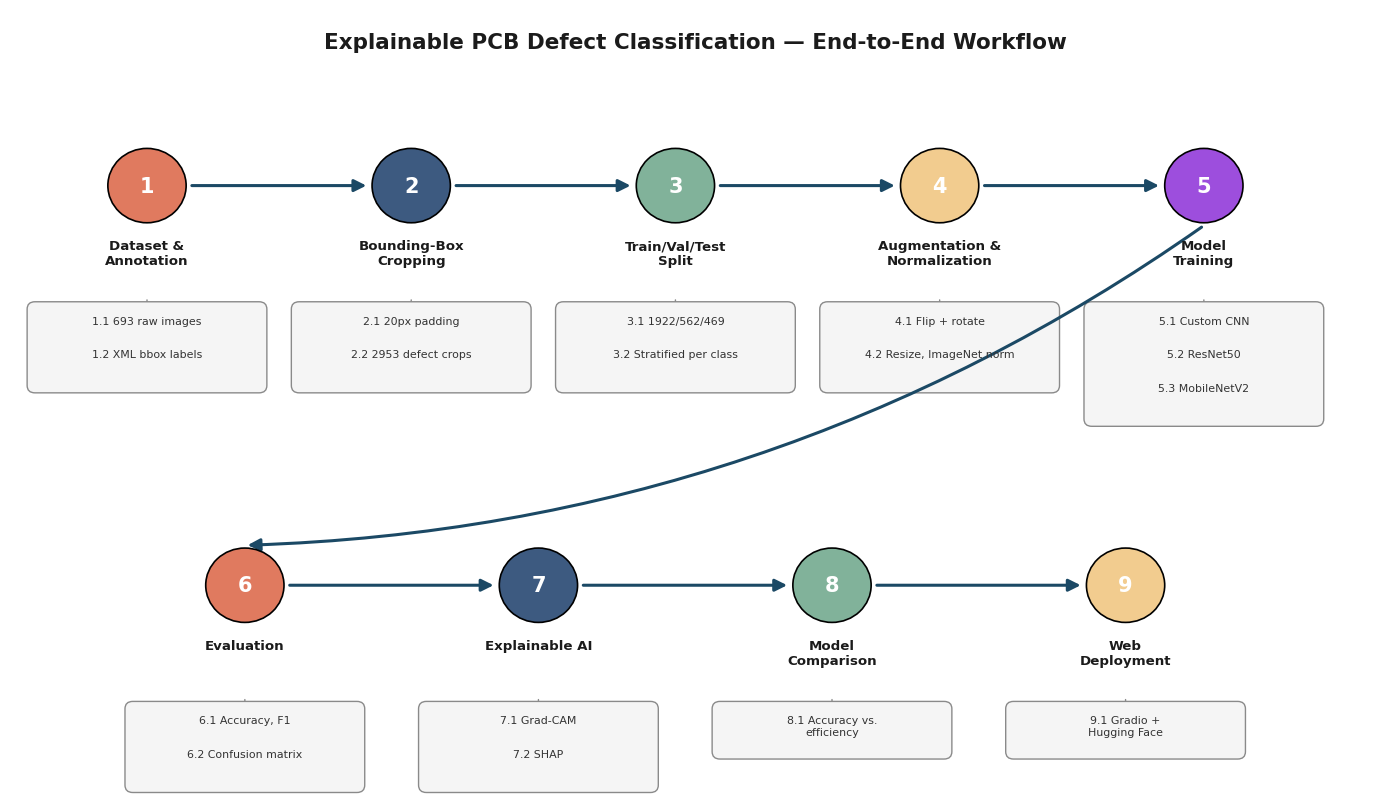

Saved workflow_figure.pdf


In [53]:
fig, ax = plt.subplots(figsize=(14, 8.2))
ax.set_xlim(0, 14)
ax.set_ylim(-0.3, 8.2)
ax.axis('off')
fig.patch.set_facecolor('white')

MAIN_ARROW = '#1b4965'
SUB_ARROW  = '#8a8a8a'
CIRCLE_COLORS = ['#e07a5f', '#3d5a80', '#81b29a', '#f2cc8f', '#9d4edd',
                  '#e07a5f', '#3d5a80', '#81b29a', '#f2cc8f']

steps = [
    (1, "Dataset &\nAnnotation", [f"1.1 {raw_total} raw images", "1.2 XML bbox labels"]),
    (2, "Bounding-Box\nCropping", ["2.1 20px padding", f"2.2 {crop_total} defect crops"]),
    (3, "Train/Val/Test\nSplit", [f"3.1 {n_train}/{n_val}/{n_test}", "3.2 Stratified per class"]),
    (4, "Augmentation &\nNormalization", ["4.1 Flip + rotate", "4.2 Resize, ImageNet norm"]),
    (5, "Model\nTraining", ["5.1 Custom CNN", "5.2 ResNet50", "5.3 MobileNetV2"]),
]
steps2 = [
    (6, "Evaluation", ["6.1 Accuracy, F1", "6.2 Confusion matrix"]),
    (7, "Explainable AI", ["7.1 Grad-CAM", "7.2 SHAP"]),
    (8, "Model\nComparison", ["8.1 Accuracy vs.\nefficiency"]),
    (9, "Web\nDeployment", ["9.1 Gradio +\nHugging Face"]),
]

row1_y, row2_y = 6.3, 2.0
x1 = [1.4, 4.1, 6.8, 9.5, 12.2]
x2 = [2.4, 5.4, 8.4, 11.4]

CIRCLE_R = 0.40
LABEL_TOP_GAP = 0.18     # gap between circle edge and label top
LABEL_RESERVE = 0.62     # fixed vertical space reserved for a (max 2-line) label
CONNECTOR_GAP = 0.10
LINE_H = 0.36            # height per sub-item line
BOX_W = 2.35

def draw_step(x, y, num, color, label, subs):
    ax.add_patch(Circle((x, y), CIRCLE_R, facecolor=color, edgecolor='black', linewidth=1.2, zorder=5))
    ax.text(x, y, str(num), ha='center', va='center', fontsize=15, fontweight='bold', color='white', zorder=6)

    label_top = y - CIRCLE_R - LABEL_TOP_GAP
    ax.text(x, label_top, label, ha='center', va='top', fontsize=9.6, fontweight='bold', color='#1b1b1b', zorder=6)

    # box top edge is a FIXED offset from the circle center regardless of label
    # line-count or number of sub-items -- this is what fixes the overlap
    box_top_edge = y - CIRCLE_R - LABEL_TOP_GAP - LABEL_RESERVE - CONNECTOR_GAP
    box_h = LINE_H * len(subs) + 0.16
    box = FancyBboxPatch((x - BOX_W/2, box_top_edge - box_h), BOX_W, box_h,
                          boxstyle="round,pad=0.05,rounding_size=0.08",
                          linewidth=1.0, edgecolor=SUB_ARROW, facecolor='#f5f5f5', zorder=3)
    ax.add_patch(box)

    for i, s in enumerate(subs):
        ax.text(x, box_top_edge - 0.10 - i*LINE_H, s, ha='center', va='top', fontsize=7.9, color='#333333', zorder=6)

    ax.add_patch(FancyArrowPatch((x, y - CIRCLE_R - LABEL_TOP_GAP - LABEL_RESERVE),
                                  (x, box_top_edge),
                                  arrowstyle='-', color=SUB_ARROW, linewidth=1.0, zorder=2))

for (num, label, subs), x in zip(steps, x1):
    draw_step(x, row1_y, num, CIRCLE_COLORS[num-1], label, subs)
for i in range(len(x1)-1):
    ax.add_patch(FancyArrowPatch((x1[i]+CIRCLE_R+0.03, row1_y), (x1[i+1]-CIRCLE_R-0.03, row1_y),
                                  arrowstyle='-|>', mutation_scale=18, color=MAIN_ARROW, linewidth=2.2, zorder=4))

for (num, label, subs), x in zip(steps2, x2):
    draw_step(x, row2_y, num, CIRCLE_COLORS[num-1], label, subs)
for i in range(len(x2)-1):
    ax.add_patch(FancyArrowPatch((x2[i]+CIRCLE_R+0.03, row2_y), (x2[i+1]-CIRCLE_R-0.03, row2_y),
                                  arrowstyle='-|>', mutation_scale=18, color=MAIN_ARROW, linewidth=2.2, zorder=4))

ax.add_patch(FancyArrowPatch((x1[-1], row1_y - CIRCLE_R - 0.03), (x2[0], row2_y + CIRCLE_R + 0.03),
                              connectionstyle="arc3,rad=-0.15",
                              arrowstyle='-|>', mutation_scale=18, color=MAIN_ARROW, linewidth=2.2, zorder=4))

ax.text(7, 7.85, "Explainable PCB Defect Classification — End-to-End Workflow",
        ha='center', va='center', fontsize=15.5, fontweight='bold', color='#1b1b1b')

plt.tight_layout()
plt.savefig('workflow_figure.pdf', format='pdf', dpi=300, facecolor='white')
plt.show()
print('Saved workflow_figure.pdf')

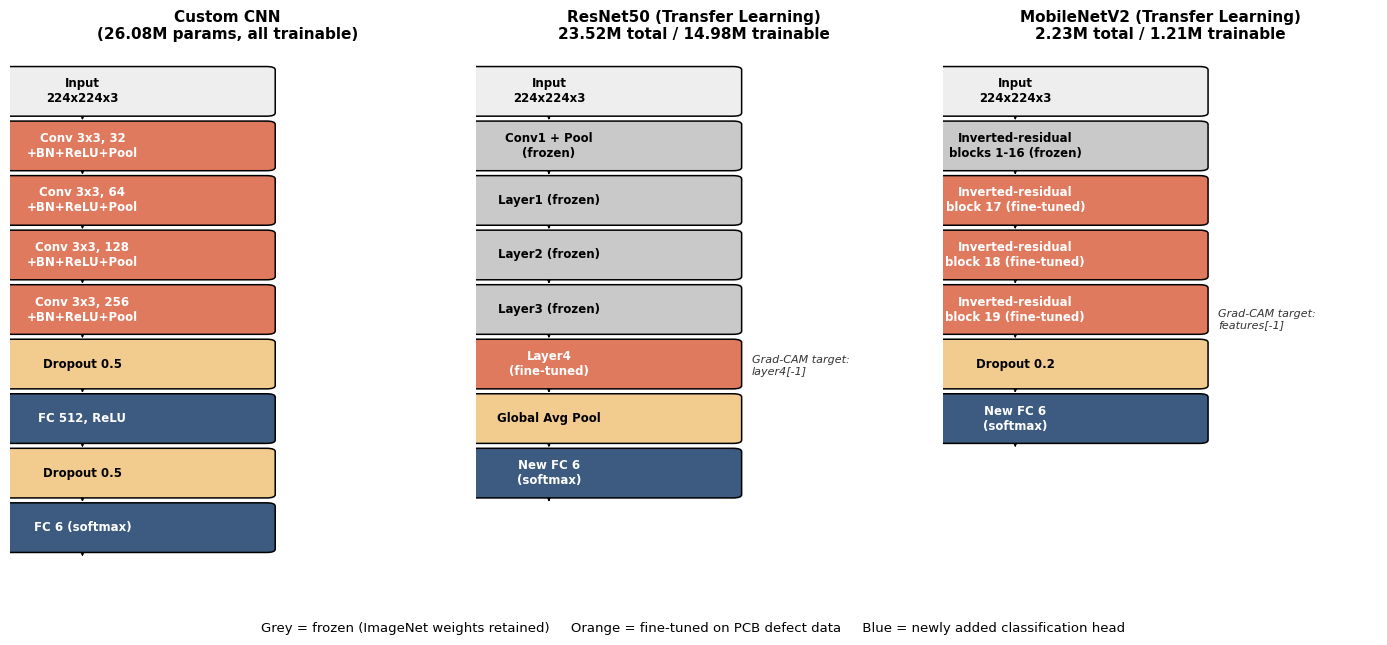

Saved architecture_comparison.pdf


In [54]:
fig, axes = plt.subplots(1, 3, figsize=(14, 6.5))
fig.patch.set_facecolor('white')
FROZEN, TRAIN, HEAD = '#c9c9c9', '#e07a5f', '#3d5a80'

def block(ax, x, y, w, h, text, color, tcolor='black', fs=8.5):
    ax.add_patch(FancyBboxPatch((x-w/2, y-h/2), w, h, boxstyle="round,pad=0.03,rounding_size=0.06",
                 linewidth=1.1, edgecolor='black', facecolor=color, zorder=3))
    ax.text(x, y, text, ha='center', va='center', fontsize=fs, color=tcolor, fontweight='bold', zorder=4)

def stack(ax, blocks, x=0.5, top=9.4, w=2.6, h=0.85, gap=0.15):
    y = top
    for text, color, tcolor in blocks:
        block(ax, x, y, w, h, text, color, tcolor)
        ax.add_patch(FancyArrowPatch((x, y-h/2), (x, y-h/2-gap), arrowstyle='-|>', mutation_scale=10, color='black'))
        y -= (h+gap)

ax = axes[0]
ax.set_xlim(0,3); ax.set_ylim(0,10.2); ax.axis('off')
ax.set_title(f"Custom CNN\n({params_custom_total/1e6:.2f}M params, all trainable)", fontsize=11, fontweight='bold')
stack(ax, [("Input\n224x224x3", '#eeeeee','black'), ("Conv 3x3, 32\n+BN+ReLU+Pool", TRAIN,'white'),
           ("Conv 3x3, 64\n+BN+ReLU+Pool", TRAIN,'white'), ("Conv 3x3, 128\n+BN+ReLU+Pool", TRAIN,'white'),
           ("Conv 3x3, 256\n+BN+ReLU+Pool", TRAIN,'white'), ("Dropout 0.5", '#f2cc8f','black'),
           ("FC 512, ReLU", HEAD,'white'), ("Dropout 0.5", '#f2cc8f','black'), ("FC 6 (softmax)", HEAD,'white')])

ax = axes[1]
ax.set_xlim(0,3); ax.set_ylim(0,10.2); ax.axis('off')
ax.set_title(f"ResNet50 (Transfer Learning)\n{params_resnet_total/1e6:.2f}M total / {params_resnet_train/1e6:.2f}M trainable", fontsize=11, fontweight='bold')
stack(ax, [("Input\n224x224x3", '#eeeeee','black'), ("Conv1 + Pool\n(frozen)", FROZEN,'black'),
           ("Layer1 (frozen)", FROZEN,'black'), ("Layer2 (frozen)", FROZEN,'black'),
           ("Layer3 (frozen)", FROZEN,'black'), ("Layer4\n(fine-tuned)", TRAIN,'white'),
           ("Global Avg Pool", '#f2cc8f','black'), ("New FC 6\n(softmax)", HEAD,'white')])
ax.annotate('Grad-CAM target:\nlayer4[-1]', xy=(1.9, 4.2), fontsize=8, style='italic', color='#333333')

ax = axes[2]
ax.set_xlim(0,3); ax.set_ylim(0,10.2); ax.axis('off')
ax.set_title(f"MobileNetV2 (Transfer Learning)\n{params_mnet_total/1e6:.2f}M total / {params_mnet_train/1e6:.2f}M trainable", fontsize=11, fontweight='bold')
stack(ax, [("Input\n224x224x3", '#eeeeee','black'), ("Inverted-residual\nblocks 1-16 (frozen)", FROZEN,'black'),
           ("Inverted-residual\nblock 17 (fine-tuned)", TRAIN,'white'), ("Inverted-residual\nblock 18 (fine-tuned)", TRAIN,'white'),
           ("Inverted-residual\nblock 19 (fine-tuned)", TRAIN,'white'), ("Dropout 0.2", '#f2cc8f','black'),
           ("New FC 6\n(softmax)", HEAD,'white')])
ax.annotate('Grad-CAM target:\nfeatures[-1]', xy=(1.9, 5.05), fontsize=8, style='italic', color='#333333')

fig.text(0.5, 0.02, "Grey = frozen (ImageNet weights retained)     Orange = fine-tuned on PCB defect data     Blue = newly added classification head",
         ha='center', fontsize=9.5)
plt.tight_layout(rect=[0,0.04,1,1])
plt.savefig('architecture_comparison.pdf', format='pdf', dpi=300, facecolor='white')
plt.show()
print('Saved architecture_comparison.pdf')

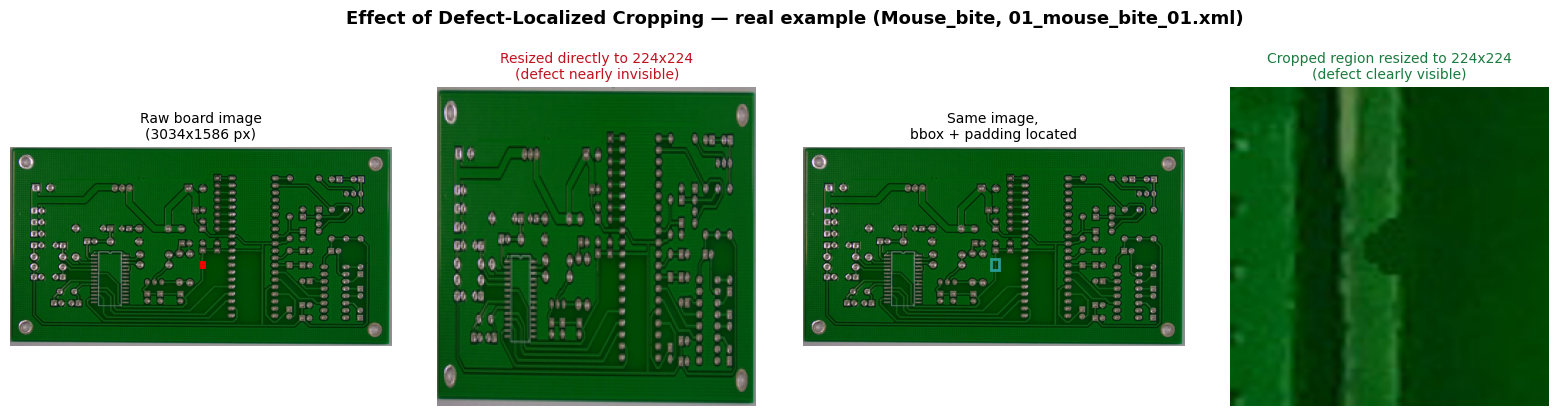

Saved before_after_cropping.pdf


In [55]:
import xml.etree.ElementTree as ET
from PIL import Image

# Pick a real annotated example — change class_name/index to try others
class_name = 'Mouse_bite'
ann_dir = os.path.join(annotations_dir, class_name)
xml_file = sorted(os.listdir(ann_dir))[0]
tree = ET.parse(os.path.join(ann_dir, xml_file))
root = tree.getroot()
img_name = xml_file.replace('.xml', '.jpg')
raw_img_path = os.path.join(images_dir, class_name, img_name)
raw_img = Image.open(raw_img_path).convert('RGB')
w, h = raw_img.size

obj = root.find('object')
bbox = obj.find('bndbox')
xmin, ymin = int(bbox.find('xmin').text), int(bbox.find('ymin').text)
xmax, ymax = int(bbox.find('xmax').text), int(bbox.find('ymax').text)
pad = 20
crop = raw_img.crop((max(0,xmin-pad), max(0,ymin-pad), min(w,xmax+pad), min(h,ymax+pad)))

full_resized = raw_img.resize((224,224))
crop_resized = crop.resize((224,224))

fig, axes = plt.subplots(1, 4, figsize=(16, 4.2))
fig.patch.set_facecolor('white')

axes[0].imshow(raw_img)
axes[0].add_patch(Rectangle((xmin,ymin), xmax-xmin, ymax-ymin, fill=False, edgecolor='red', linewidth=2))
axes[0].set_title(f"Raw board image\n({w}x{h} px)", fontsize=10)
axes[0].axis('off')

axes[1].imshow(full_resized)
axes[1].set_title("Resized directly to 224x224\n(defect nearly invisible)", fontsize=10, color='#c1121f')
axes[1].axis('off')

axes[2].imshow(raw_img)
axes[2].add_patch(Rectangle((max(0,xmin-pad), max(0,ymin-pad)), (xmax-xmin)+2*pad, (ymax-ymin)+2*pad,
                             fill=False, edgecolor='#2a9d8f', linewidth=2))
axes[2].set_title("Same image,\nbbox + padding located", fontsize=10)
axes[2].axis('off')

axes[3].imshow(crop_resized)
axes[3].set_title("Cropped region resized to 224x224\n(defect clearly visible)", fontsize=10, color='#1b7a3d')
axes[3].axis('off')

fig.suptitle(f"Effect of Defect-Localized Cropping — real example ({class_name}, {xml_file})", fontsize=13, fontweight='bold')
plt.tight_layout(rect=[0,0,1,0.93])
plt.savefig('before_after_cropping.pdf', format='pdf', dpi=300, facecolor='white')
plt.show()
print('Saved before_after_cropping.pdf')

In [56]:
import shutil, os


figures_for_overleaf = [
    "graphical_abstract.pdf",
    "workflow_figure.pdf",
    "before_after_cropping.pdf",
    "architecture_comparison.pdf",
    "confusion_matrix_all_models.pdf",
]

os.makedirs("overleaf_figures", exist_ok=True)
missing = []
for f in figures_for_overleaf:
    if os.path.exists(f):
        shutil.copy(f, f"overleaf_figures/{f}")
    else:
        missing.append(f)

shutil.make_archive("overleaf_figures", "zip", "overleaf_figures")

print("Bundled:")
for f in figures_for_overleaf:
    if f not in missing:
        print(f"  ✓ {f}")
if missing:
    print("Missing (not found):")
    for f in missing:
        print(f"  ✗ {f}")

from IPython.display import FileLink
FileLink("overleaf_figures.zip")

Bundled:
  ✓ graphical_abstract.pdf
  ✓ workflow_figure.pdf
  ✓ before_after_cropping.pdf
  ✓ architecture_comparison.pdf
  ✓ confusion_matrix_all_models.pdf


/kaggle/working/overleaf_figures.zip